# Da trajetória individual à rede de coautoria

Este caderno cruza o perfil público do Google Scholar de **Rafael Luiz Araujo de Mesquita** com a lista local de inscritos da XI SBGEA 2026. A visualização coloca Rafael no centro e destaca participantes ligados a ele por coautoria em **1, 2 ou 3 passos**.

A rede mostra relações bibliográficas observáveis; não mede proximidade pessoal, influência, qualidade ou colaboração futura. A terceira camada é reportada como **mínimo confirmado**, porque as fontes abertas disponíveis não permitiram identificar todos os perfis de participantes sem ambiguidade.

In [10]:
from pathlib import Path
import json, os, re, math, unicodedata, textwrap, sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle, FancyBboxPatch
from IPython.display import display, Markdown

# Locate the source checkout from any notebook working directory and add its package.
PROJECT_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside this checkout or one of its subdirectories.")
sys.path.insert(0, str(PROJECT_DIR / "src")) if str(PROJECT_DIR / "src") not in sys.path else None
from sbgea_keynote.paths import input_path, output_dir, output_path

DATA_DIR = input_path("science_network", "snapshots")
ATTENDEE_FILE = input_path("registration", "inscritos_SBGEA.xlsx")
FIGURE_DIR = output_dir("figures", "science_network")
OUTPUT_FIGURE = FIGURE_DIR / "ScienceNetwork.png"

# Use Helvetica Neue's condensed width where available. The system's Helvetica Neue
# family contains condensed bold faces; regular text falls back within the same family.
FONT_FAMILY = "Helvetica Neue"
mpl.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.stretch": "condensed",
    "font.size": 10,
    "axes.unicode_minus": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})
try:
    FONT_PATH = fm.findfont(fm.FontProperties(family=FONT_FAMILY, stretch="condensed"), fallback_to_default=False)
except Exception:
    FONT_FAMILY = "Arial Narrow"
    mpl.rcParams["font.family"] = FONT_FAMILY
    FONT_PATH = fm.findfont(FONT_FAMILY)

COLORS = {
    "navy": "#082F73",
    "blue": "#3E8EDE",
    "green": "#70AE54",
    "orange": "#EC8135",
    "ink": "#25364A",
    "muted": "#63758A",
    "line": "#D5DEE8",
    "pale": "#E8EEF5",
    "white": "#FFFFFF",
}
print(f"Pasta do projeto: {PROJECT_DIR}")
print(f"Fonte em uso: {FONT_FAMILY} ({FONT_PATH})")

Pasta do projeto: $KEYNOTETALK_PROJECT
Fonte em uso: Helvetica Neue (/System/Library/Fonts/HelveticaNeue.ttc)


## Fontes, definição da rede e limites

- O perfil público do [Google Scholar](https://scholar.google.com/citations?user=wxqC8f4AAAAJ&hl=en) fornece a lista de trabalhos de Rafael. A captura local tem 54 entradas.
- [OpenAlex](https://openalex.org/A5029374074) fornece identificadores de autores e relações por coautoria. Nesta captura, 37 trabalhos do perfil têm autoria estruturada, gerando 181 coautores diretos e 11.174 autores distintos no segundo salto.
- A lista `inscritos_SBGEA.xlsx` fica no computador; este caderno não a envia a nenhum serviço. As buscas de nomes foram feitas apenas contra perfis bibliográficos públicos.
- Uma aresta significa que duas pessoas aparecem como coautoras de pelo menos um trabalho indexado. O grau de cada participante é o menor número de arestas desde Rafael.

A busca anônima do OpenAlex esgotou o orçamento diário compartilhado durante a expansão do terceiro salto. Para não transformar ausência de dados em “não conectado”, quatro rotas de terceiro grau identificadas numa checagem complementar do Semantic Scholar são mostradas como **mínimo**, não como contagem exaustiva. O caderno inclui uma função opcional para completar essa etapa com uma chave própria do OpenAlex.

In [11]:
# Load the saved public-source snapshots and the private attendee workbook.
required = [
    ATTENDEE_FILE,
    DATA_DIR / "scholar_profile_works.json",
    DATA_DIR / "openalex_root_works.json",
    DATA_DIR / "first_degree_neighborhoods.json",
    DATA_DIR / "attendee_author_search.json",
    DATA_DIR / "semanticscholar_attendee_papers.json",
]
missing = [str(x) for x in required if not x.exists()]
if missing:
    raise FileNotFoundError("Missing local input(s):\n" + "\n".join(missing))

scholar_snapshot = json.loads((DATA_DIR / "scholar_profile_works.json").read_text())
root_snapshot = json.loads((DATA_DIR / "openalex_root_works.json").read_text())
neighborhood_snapshot = json.loads((DATA_DIR / "first_degree_neighborhoods.json").read_text())
attendee_search = json.loads((DATA_DIR / "attendee_author_search.json").read_text())["results"]
semantic_snapshot = json.loads((DATA_DIR / "semanticscholar_attendee_papers.json").read_text())["profiles"]
attendees = pd.read_excel(ATTENDEE_FILE).fillna("")
NAME_COL = "Nome para o CRACHÁ:"
INSTITUTION_COL = "Instituição de vínculo:"
attendees[NAME_COL] = attendees[NAME_COL].astype(str).str.strip()

ROOT_ID = "A5029374074"
ROOT_NAME = "Rafael Luiz Araujo de Mesquita"
root_works = root_snapshot["results"]
neighborhoods = neighborhood_snapshot["neighborhoods"]

# Deduplicate authors by OpenAlex ID, never by display name alone.
root_author_names = {}
for work in root_works:
    for authorship in work.get("authorships", []):
        author = authorship.get("author") or {}
        author_id = author.get("id")
        if author_id:
            root_author_names[author_id.rsplit("/", 1)[-1]] = author.get("display_name", "")
first_ids = set(root_author_names) - {ROOT_ID}
second_name_by_id = {}
second_parents = {}
for parent_id, record in neighborhoods.items():
    for neighbor in record.get("neighbors", []):
        child_id = neighbor["id"]
        if child_id == ROOT_ID or child_id in first_ids:
            continue
        second_name_by_id.setdefault(child_id, neighbor["name"])
        second_parents.setdefault(child_id, []).append({
            "parent_id": parent_id,
            "parent_name": root_author_names.get(parent_id, parent_id),
            "shared_works": neighbor.get("works", 0),
        })

print(f"Google Scholar: {len(scholar_snapshot['works'])} trabalhos na captura")
print(f"OpenAlex: {len(root_works)} trabalhos com autoria estruturada")
print(f"Colaboradores diretos: {len(first_ids):,}")
print(f"Autores distintos no segundo salto: {len(second_name_by_id):,}")
print(f"Inscrições lidas localmente: {len(attendees)}")

Google Scholar: 54 trabalhos na captura
OpenAlex: 37 trabalhos com autoria estruturada
Colaboradores diretos: 181
Autores distintos no segundo salto: 11,174
Inscrições lidas localmente: 106


## Resolução dos nomes

O crachá não é um identificador acadêmico: alguns nomes estão abreviados e alguns autores têm nomes iguais. Por isso, a correspondência abaixo exige evidência de nome e de contexto institucional, e os casos com abreviações ou perfis duplicados ficam marcados como confiança média. Cada pessoa é contada uma única vez, pela rota mais curta.

As quatro ligações diretas são conferidas nos trabalhos de Rafael. As ligações de segundo grau são conferidas por IDs de autor do OpenAlex. Para o terceiro grau, cada rota inclui a pessoa intermediária e uma publicação que traz o coautor correspondente.

In [12]:
# Curated matches: names exactly as they appear in the attendee workbook.
# IDs come from the saved bibliographic graph/profile lookup. The evidence column
# records how each display-name variant was reconciled.
DIRECT_MATCHES = [
    {"attendee": "Inez Staciarini Batista", "id": "A5016940461", "profile": "Inez Staciarini Batista", "confidence": "Alta", "evidence": "Nome completo e coautoria direta"},
    {"attendee": "Jonas R. Souza", "id": "A5070704055", "profile": "J. R. Souza", "confidence": "Alta", "evidence": "Iniciais, sobrenome e vínculo INPE; coautoria direta"},
    {"attendee": "Ângela Santos", "id": "A5113976357", "profile": "A. M. Santos", "confidence": "Alta", "evidence": "Iniciais, sobrenome e vínculo INPE; coautoria direta"},
    {"attendee": "Cristiano M. Wrasse", "id": "A5059811668", "profile": "C. M. Wrasse", "confidence": "Alta", "evidence": "Iniciais, sobrenome e vínculo INPE; coautoria direta"},
]

SECOND_MATCHES = [
    {"attendee": "Karen J C Ferreira", "id": "A5002617204", "profile": "Karen Júlia Coldebella Ferreira", "confidence": "Alta", "evidence": "Nome expandido e afiliação INPE"},
    {"attendee": "Igo Paulino", "id": "A5021678057", "profile": "Igo Paulino", "confidence": "Alta", "evidence": "Nome completo e afiliação UFCG"},
    {"attendee": "Ana Roberta Paulino", "id": "A5013782971", "profile": "Ana Roberta Paulino", "confidence": "Alta", "evidence": "Nome completo e afiliação UEPB"},
    {"attendee": "Paulo P. Batista", "id": "A5038134380", "profile": "P. P. Batista", "confidence": "Alta", "evidence": "Iniciais, sobrenome e afiliação INPE"},
    {"attendee": "Rodolfo de Jesus", "id": "A5003153404", "profile": "R. de Jesus", "confidence": "Alta", "evidence": "Nome/sobrenome e afiliação INPE"},
    {"attendee": "Paulo R Fagundes", "id": "A5083339670", "profile": "Paulo Roberto Fagundes", "confidence": "Alta", "evidence": "Nome expandido e afiliação UNIVAP"},
    {"attendee": "José P. Marchezi", "id": "A5006972287", "profile": "J. P. Marchezi", "confidence": "Alta", "evidence": "Iniciais, sobrenome e afiliação INPE"},
    {"attendee": "Marlos Rockenbach", "id": "A5083070013", "profile": "Marlos Rockenbach", "confidence": "Alta", "evidence": "Nome completo e afiliação INPE"},
    {"attendee": "Fabio Egito", "display": "Fábio Egito", "id": "A5004812337", "profile": "Fábio Egito", "confidence": "Alta", "evidence": "Nome completo e afiliação UFCG"},
    {"attendee": "Vania Andrioli", "id": "A5016190744", "profile": "V. F. Andrioli", "confidence": "Alta", "evidence": "Iniciais, sobrenome e afiliação INPE"},
    {"attendee": "Jean C. Santos", "id": "A5065163209", "profile": "Jean Carlo Santos", "confidence": "Média", "evidence": "Nome expandido compatível; afiliação do perfil não informada"},
    {"attendee": "Laysa Resende", "id": "A5009556168", "profile": "L. C. A. Resende", "confidence": "Média", "evidence": "Perfil INPE compatível; há registros bibliográficos duplicados"},
    {"attendee": "Alisson Dal Lago", "id": "A5018247488", "profile": "A. Dal Lago", "confidence": "Alta", "evidence": "Nome, sobrenome e afiliação INPE"},
    {"attendee": "HISAO TAKAHASHI", "display": "Hisao Takahashi", "id": "A5088257343", "profile": "H. Takahashi", "confidence": "Média", "evidence": "Nome completo compatível com perfil abreviado INPE"},
    {"attendee": "Paulo R Jauer", "id": "A5091089819", "profile": "Paulo Ricardo Jauer", "confidence": "Alta", "evidence": "Nome expandido e afiliação INPE"},
]

# These four third-step routes were checked against actual coauthor lists in the
# local Semantic Scholar snapshot and against the OpenAlex second-step graph.
# They are a minimum confirmed set, not an exhaustive third-degree search.
THIRD_MATCHES = [
    {"attendee": "Hadassa Jácome", "candidate_id": "A5069675248", "candidate_profile": "Hadassa Raquel Peixoto Jácome", "bridge_id": "A5016003011", "bridge_name": "Gilvan Luiz Borba", "parent_id": "A5070704055", "parent_name": "J. R. Souza", "s2_author_id": "101862842", "s2_profile": "H. Jácome", "paper_year": 2018, "paper_title": "POSSÍVEL TID GERADO NA REGIÃO POLAR E OBSERVADO SOBRE ESTAÇÕES EQUATORIAIS E DE BAIXAS LATITUDES", "coauthor_as_listed": "G. L. Borba", "confidence": "Média"},
    {"attendee": "Luiz F. Ziebell", "candidate_id": "A5048735989", "candidate_profile": "L. F. Ziebell", "bridge_id": "A5014791457", "bridge_name": "Stefaan Poedts", "parent_id": "A5018566497", "parent_name": "V. G. Merkin", "s2_author_id": "5104105", "s2_profile": "L. F. Ziebell", "paper_year": 2026, "paper_title": "Dynamic spectra of type III radio emissions from particle-in-cell simulations", "coauthor_as_listed": "S. Poedts", "confidence": "Alta"},
    {"attendee": "Solomon M. Perriyil", "candidate_id": "A5119095395", "candidate_profile": "Solomon M. Perriyil", "bridge_id": "A5042997663", "bridge_name": "Jiong Qiu", "parent_id": "A5062312270", "parent_name": "Youjun Deng", "s2_author_id": "2373846470", "s2_profile": "Solomon M. Perriyil", "paper_year": 2025, "paper_title": "High-resolution Observations of an X6.4 Solar Flare in the Mid-infrared", "coauthor_as_listed": "Jiong Qiu", "confidence": "Alta"},
    {"attendee": "Adriany Barbosa", "candidate_id": "A5159045339", "candidate_profile": "Adriany Barbosa", "bridge_id": "A5008873396", "bridge_name": "L. E. A. Vieira", "parent_id": "A5113976357", "parent_name": "A. M. Santos", "s2_author_id": "2484844247", "s2_profile": "Adriany Rodrigues Barbosa", "paper_year": 2026, "paper_title": "Short-term Forecasting of Total Solar Irradiance from Solar Disk Images: A Hybrid Unsupervised Deep Learning Approach", "coauthor_as_listed": "L. E. Antunes Vieira", "confidence": "Média"},
]

# Validate that every path is real in the cached graph, and that its final edge is
# supported by the cached publication author list.
def normalize_tokens(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(ch for ch in value if not unicodedata.combining(ch))
    return re.sub(r"[^a-z0-9 ]", " ", value.casefold()).split()

def initials_compatible(a, b):
    ta, tb = normalize_tokens(a), normalize_tokens(b)
    if len(ta) < 2 or len(tb) < 2 or ta[-1] != tb[-1] or ta[0][0] != tb[0][0]:
        return False
    ma, mb = [x[0] for x in ta[1:-1]], [x[0] for x in tb[1:-1]]
    n = min(len(ma), len(mb))
    return ma[:n] == mb[:n]

first_name_by_id = root_author_names
assert len(first_ids) == 181
assert len(second_name_by_id) == 11174
for match in DIRECT_MATCHES:
    assert match["id"] in first_ids, match
for match in SECOND_MATCHES:
    assert match["id"] in second_name_by_id, match
for match in THIRD_MATCHES:
    assert match["candidate_id"] not in first_ids | set(second_name_by_id)
    assert match["bridge_id"] in second_name_by_id
    assert match["parent_id"] in first_ids
    assert any(n["id"] == match["bridge_id"] for n in neighborhoods[match["parent_id"]]["neighbors"])
    s2 = semantic_snapshot[match["s2_author_id"]]
    evidence = [w for w in s2["papers"] if w.get("year") == match["paper_year"] and w.get("title") == match["paper_title"]]
    assert evidence, (match["attendee"], "paper absent from cached source")
    listed_authors = [a.get("name", "") for w in evidence for a in w.get("authors", [])]
    assert any(initials_compatible(match["coauthor_as_listed"], a) for a in listed_authors), match
    assert initials_compatible(match["coauthor_as_listed"], match["bridge_name"]), match

print("IDs, shortest paths, and supplementary third-degree paper evidence validated.")

IDs, shortest paths, and supplementary third-degree paper evidence validated.


In [13]:
# Make one table with the shortest known path for each matched attendee.
# For a second-step match, select one documented first-degree intermediary.
def representative_parent(author_id):
    choices = second_parents.get(author_id, [])
    if not choices:
        raise KeyError(f"No first-degree path to {author_id}")
    return max(choices, key=lambda x: (x["shared_works"], x["parent_id"]))

records = []
for m in DIRECT_MATCHES:
    records.append({
        "participante": m.get("display", m["attendee"]), "nome no crachá": m["attendee"], "grau": 1, "perfil bibliográfico": m["profile"],
        "rota mais curta": f"Rafael → {m['attendee']}", "confiança": m["confidence"], "evidência": m["evidence"],
    })
for m in SECOND_MATCHES:
    p = representative_parent(m["id"])
    records.append({
        "participante": m.get("display", m["attendee"]), "nome no crachá": m["attendee"], "grau": 2, "perfil bibliográfico": m["profile"],
        "rota mais curta": f"Rafael → {p['parent_name']} → {m['attendee']}", "confiança": m["confidence"], "evidência": m["evidence"],
    })
for m in THIRD_MATCHES:
    records.append({
        "participante": m.get("display", m["attendee"]), "nome no crachá": m["attendee"], "grau": 3, "perfil bibliográfico": m["candidate_profile"],
        "rota mais curta": f"Rafael → {m['parent_name']} → {m['bridge_name']} → {m['attendee']}",
        "confiança": m["confidence"],
        "evidência": f"{m['paper_year']}: {m['paper_title']} (Semantic Scholar)",
    })

matches = pd.DataFrame(records).sort_values(["grau", "participante"]).reset_index(drop=True)
assert matches["participante"].is_unique, "An attendee must only be counted once."

attendee_names = set(attendees[NAME_COL].astype(str).str.strip())
missing_attendee_names = sorted(set(matches["nome no crachá"]) - attendee_names)
assert not missing_attendee_names, f"Names not present in workbook: {missing_attendee_names}"
central_rows = attendees[attendees[NAME_COL].str.casefold().eq("rafael mesquita")]
assert len(central_rows) == 1, "Expected one Rafael Mesquita row in the attendee workbook."

summary = (matches.groupby("grau").size().reindex([1, 2, 3], fill_value=0).rename("participantes").to_frame())
summary.index = ["1º grau", "2º grau", "3º grau — mínimo confirmado"]
not_confirmed = len(attendees) - len(central_rows) - len(matches)
print(f"Participantes na lista, sem Rafael: {len(attendees) - len(central_rows)}")
display(summary)
print(f"Correspondências verificadas (graus 1–2): {int(summary.iloc[0,0] + summary.iloc[1,0])}")
print(f"Terceiro grau: pelo menos {int(summary.iloc[2,0])}; expansão parcial, portanto a contagem total pode ser maior.")
print(f"Sem rota confirmada nesta análise: {not_confirmed} (isso não demonstra ausência de colaboração).")
display(matches)

Participantes na lista, sem Rafael: 105


,participantes
1º grau,4
2º grau,15
3º grau — mínimo confirmado,4


Correspondências verificadas (graus 1–2): 19
Terceiro grau: pelo menos 4; expansão parcial, portanto a contagem total pode ser maior.
Sem rota confirmada nesta análise: 82 (isso não demonstra ausência de colaboração).


,participante,nome no crachá,grau,perfil bibliográfico,rota mais curta,confiança,evidência
0,Cristiano M. Wrasse,Cristiano M. Wrasse,1,C. M. Wrasse,Rafael → Cristiano M. Wrasse,Alta,"Iniciais, sobrenome e vínculo INPE; coautoria ..."
1,Inez Staciarini Batista,Inez Staciarini Batista,1,Inez Staciarini Batista,Rafael → Inez Staciarini Batista,Alta,Nome completo e coautoria direta
2,Jonas R. Souza,Jonas R. Souza,1,J. R. Souza,Rafael → Jonas R. Souza,Alta,"Iniciais, sobrenome e vínculo INPE; coautoria ..."
3,Ângela Santos,Ângela Santos,1,A. M. Santos,Rafael → Ângela Santos,Alta,"Iniciais, sobrenome e vínculo INPE; coautoria ..."
4,Alisson Dal Lago,Alisson Dal Lago,2,A. Dal Lago,Rafael → C. M. Wrasse → Alisson Dal Lago,Alta,"Nome, sobrenome e afiliação INPE"
5,Ana Roberta Paulino,Ana Roberta Paulino,2,Ana Roberta Paulino,Rafael → R. A. Buriti → Ana Roberta Paulino,Alta,Nome completo e afiliação UEPB
6,Fábio Egito,Fabio Egito,2,Fábio Egito,Rafael → R. A. Buriti → Fabio Egito,Alta,Nome completo e afiliação UFCG
7,Hisao Takahashi,HISAO TAKAHASHI,2,H. Takahashi,Rafael → C. M. Wrasse → HISAO TAKAHASHI,Média,Nome completo compatível com perfil abreviado ...
8,Igo Paulino,Igo Paulino,2,Igo Paulino,Rafael → R. A. Buriti → Igo Paulino,Alta,Nome completo e afiliação UFCG
9,Jean C. Santos,Jean C. Santos,2,Jean Carlo Santos,Rafael → C. M. Wrasse → Jean C. Santos,Média,Nome expandido compatível; afiliação do perfil...


## Visualização da rede

As posições servem apenas para separar visualmente as camadas; não representam localização, importância ou força científica. Os pontos cinza do segundo anel são uma amostra visual da rede. As arestas destacadas são rotas reais verificadas no material bibliográfico salvo.

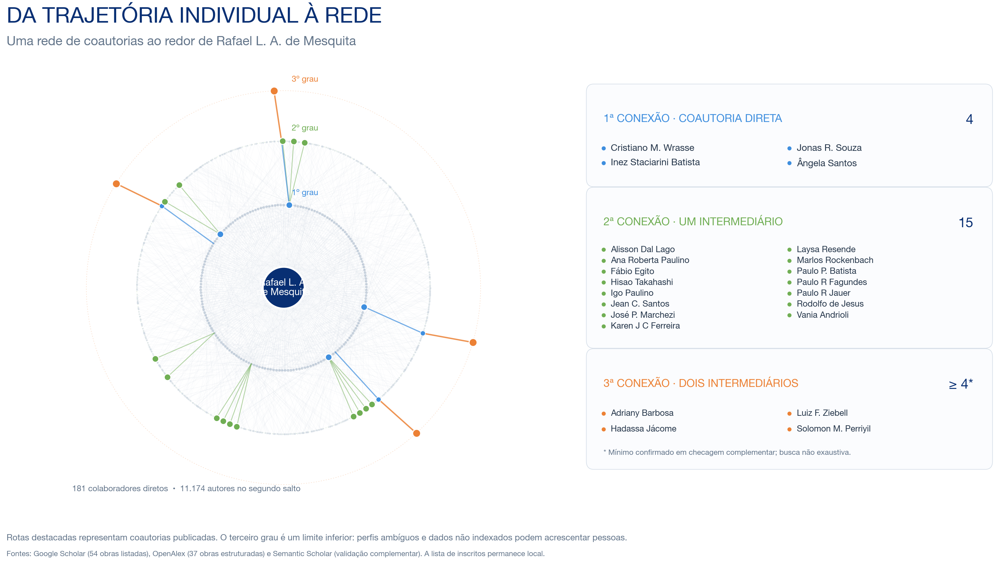

Figura salva em: $SBGEA_KEYNOTE_DATA/outputs/figures/science_network/ScienceNetwork.png


In [14]:
# Deterministic radial layout: all first-degree author nodes are represented;
# second-step background nodes are a reproducible sample, with actual attendee
# paths highlighted on top of the sample.
fig = plt.figure(figsize=(16, 9), dpi=200, constrained_layout=False)
gs = fig.add_gridspec(1, 2, width_ratios=[1.16, 0.84], left=0.035, right=0.98, top=0.86, bottom=0.10, wspace=0.04)
ax_net = fig.add_subplot(gs[0, 0])
ax_info = fig.add_subplot(gs[0, 1])

fig.text(0.04, 0.955, "DA TRAJETÓRIA INDIVIDUAL À REDE", color=COLORS["navy"],
         fontsize=24, fontweight="bold", ha="left", va="top")
fig.text(0.04, 0.905, "Uma rede de coautorias ao redor de Rafael L. A. de Mesquita", color=COLORS["muted"],
         fontsize=14, ha="left", va="top")

# Stable node positions for 181 direct collaborators.
first_sorted = sorted(first_ids)
first_angles = {aid: 2 * np.pi * i / len(first_sorted) + np.pi / 2 for i, aid in enumerate(first_sorted)}
first_pos = {aid: (1.0 * np.cos(first_angles[aid]), 1.0 * np.sin(first_angles[aid])) for aid in first_ids}
root_xy = (0.0, 0.0)

# Draw the first ring and root-to-collaborator edges.
root_edges = [(root_xy, first_pos[aid]) for aid in first_ids]
ax_net.add_collection(LineCollection(root_edges, colors=COLORS["line"], linewidths=0.34, alpha=0.40, zorder=1))
ax_net.scatter([first_pos[a][0] for a in first_ids], [first_pos[a][1] for a in first_ids],
               s=8, color="#AAB8C8", alpha=0.55, linewidths=0, zorder=2)

# Sample the broader second-step population, but force inclusion of all highlighted
# attendee nodes and third-step bridge authors.
all_second_ids = sorted(second_name_by_id)
needed_second = {m["id"] for m in SECOND_MATCHES} | {m["bridge_id"] for m in THIRD_MATCHES}
rng = np.random.default_rng(20261024)
remaining = [x for x in all_second_ids if x not in needed_second]
sample_n = min(900, len(remaining))
background_ids = set(rng.choice(remaining, size=sample_n, replace=False).tolist()) | needed_second
background_angles = {aid: float(rng.uniform(0, 2*np.pi)) for aid in background_ids}
second_pos = {aid: (1.77*np.cos(theta), 1.77*np.sin(theta)) for aid, theta in background_angles.items()}
# Real parent-to-neighbor links for the sampled background nodes.
background_edges = []
for aid in background_ids - needed_second:
    parents = second_parents.get(aid, [])
    if not parents:
        continue
    parent = max(parents, key=lambda x: (x["shared_works"], x["parent_id"]))["parent_id"]
    background_edges.append((first_pos[parent], second_pos[aid]))
ax_net.add_collection(LineCollection(background_edges, colors="#D6DEE8", linewidths=0.26, alpha=0.22, zorder=0))
ax_net.scatter([second_pos[a][0] for a in background_ids - needed_second],
               [second_pos[a][1] for a in background_ids - needed_second],
               s=4, color="#CFD8E2", alpha=0.38, linewidths=0, zorder=1)

# A participant's representative second-step parent is the direct collaborator
# with the largest OpenAlex coauthor count in that cached neighborhood.
second_attendee_pos = {}
second_parent_for_attendee = {}
by_parent = {}
for m in SECOND_MATCHES:
    p = representative_parent(m["id"])
    second_parent_for_attendee[m["id"]] = p["parent_id"]
    by_parent.setdefault(p["parent_id"], []).append(m["id"])
for parent_id, ids in by_parent.items():
    ids = sorted(ids)
    offsets = np.linspace(-0.075, 0.075, len(ids)) if len(ids) > 1 else np.array([0.0])
    base_angle = first_angles[parent_id]
    for aid, offset in zip(ids, offsets):
        theta = base_angle + float(offset)
        second_attendee_pos[aid] = (1.77*np.cos(theta), 1.77*np.sin(theta))
        second_pos[aid] = second_attendee_pos[aid]
        ax_net.plot([first_pos[parent_id][0], second_pos[aid][0]],
                    [first_pos[parent_id][1], second_pos[aid][1]],
                    color=COLORS["green"], alpha=0.52, lw=0.9, zorder=3)

# Draw the four representative third-step bridges and attendee nodes.
third_pos = {}
for i, m in enumerate(THIRD_MATCHES):
    bridge_id, parent_id = m["bridge_id"], m["parent_id"]
    theta = first_angles[parent_id] + (i - 1.5) * 0.055
    second_pos[bridge_id] = (1.77*np.cos(theta), 1.77*np.sin(theta))
    theta3 = theta + 0.035
    third_pos[m["attendee"]] = (2.38*np.cos(theta3), 2.38*np.sin(theta3))
    ax_net.plot([first_pos[parent_id][0], second_pos[bridge_id][0]],
                [first_pos[parent_id][1], second_pos[bridge_id][1]],
                color=COLORS["blue"], alpha=0.72, lw=1.2, zorder=4)
    ax_net.plot([second_pos[bridge_id][0], third_pos[m["attendee"]][0]],
                [second_pos[bridge_id][1], third_pos[m["attendee"]][1]],
                color=COLORS["orange"], alpha=0.85, lw=1.5, zorder=5)
    ax_net.scatter(*second_pos[bridge_id], s=30, color=COLORS["blue"], edgecolor="white", linewidth=0.6, zorder=6)
    ax_net.scatter(*third_pos[m["attendee"]], s=76, color=COLORS["orange"], edgecolor="white", linewidth=1.1, zorder=8)

# Direct attendee nodes.
direct_ids = {m["id"] for m in DIRECT_MATCHES}
ax_net.scatter([first_pos[a][0] for a in direct_ids], [first_pos[a][1] for a in direct_ids],
               s=52, color=COLORS["blue"], edgecolor="white", linewidth=1.0, zorder=7)
# Second-degree attendee nodes.
second_ids = {m["id"] for m in SECOND_MATCHES}
ax_net.scatter([second_pos[a][0] for a in second_ids], [second_pos[a][1] for a in second_ids],
               s=52, color=COLORS["green"], edgecolor="white", linewidth=1.0, zorder=7)
# Central person.
ax_net.scatter([0], [0], s=2100, color=COLORS["navy"], edgecolor="white", linewidth=2.0, zorder=10)
ax_net.text(0, 0, "Rafael L. A.\nde Mesquita", color="white", fontsize=10.5, fontweight="bold",
            ha="center", va="center", zorder=11, linespacing=1.05)

# Degree guide rings and labels.
for radius, label, color in [(1.0, "1º grau", COLORS["blue"]), (1.77, "2º grau", COLORS["green"]), (2.38, "3º grau", COLORS["orange"])]:
    ax_net.add_patch(Circle((0, 0), radius, fill=False, lw=0.55, linestyle=(0, (2, 3)), edgecolor=color, alpha=0.28, zorder=0))
ax_net.text(0.10, 1.10, "1º grau", color=COLORS["blue"], fontsize=9, ha="left", va="bottom")
ax_net.text(0.10, 1.88, "2º grau", color=COLORS["green"], fontsize=9, ha="left", va="bottom")
ax_net.text(0.10, 2.47, "3º grau", color=COLORS["orange"], fontsize=9, ha="left", va="bottom")
ax_net.text(-2.55, -2.48, "181 colaboradores diretos  •  11.174 autores no segundo salto",
            fontsize=9, color=COLORS["muted"], ha="left", va="bottom")
ax_net.set_aspect("equal")
ax_net.set_xlim(-2.75, 2.75)
ax_net.set_ylim(-2.70, 2.72)
ax_net.axis("off")

# Right side: attendee names and distinct shortest-path counts.
ax_info.axis("off")
ax_info.set_xlim(0, 1)
ax_info.set_ylim(0, 1)

def panel_card(y, height, title, count_text, accent, names, columns=1, font_size=10.5, note=None):
    card = FancyBboxPatch((0.015, y), 0.97, height,
                          boxstyle="round,pad=0.012,rounding_size=0.018",
                          linewidth=0.65, edgecolor=COLORS["line"], facecolor="#FBFCFE",
                          transform=ax_info.transAxes, clip_on=False)
    ax_info.add_patch(card)
    ax_info.text(0.045, y + height - 0.055, title.upper(), transform=ax_info.transAxes,
                 fontsize=12, fontweight="bold", color=accent, va="top")
    ax_info.text(0.95, y + height - 0.055, count_text, transform=ax_info.transAxes,
                 fontsize=15, fontweight="bold", color=COLORS["navy"], va="top", ha="right")
    body_top = y + height - 0.115
    body_bottom = y + 0.025 + (0.035 if note else 0)
    rows = math.ceil(len(names) / columns)
    step = (body_top - body_bottom) / max(rows, 1)
    for i, name in enumerate(names):
        col = i // rows
        row = i % rows
        x = 0.045 + col * (0.91 / columns)
        yy = body_top - (row + 0.5) * step
        ax_info.scatter([x], [yy], transform=ax_info.transAxes, s=12, color=accent, zorder=2)
        ax_info.text(x + 0.018, yy, name, transform=ax_info.transAxes, fontsize=font_size,
                     color=COLORS["ink"], va="center", ha="left")
    if note:
        ax_info.text(0.045, y + 0.018, note, transform=ax_info.transAxes, fontsize=8.3,
                     color=COLORS["muted"], va="bottom")

names_by_degree = {d: matches.loc[matches["grau"].eq(d), "participante"].tolist() for d in [1,2,3]}
panel_card(0.735, 0.205, "1ª conexão · coautoria direta", f"{len(names_by_degree[1])}", COLORS["blue"],
           names_by_degree[1], columns=2, font_size=10.2)
panel_card(0.375, 0.335, "2ª conexão · um intermediário", f"{len(names_by_degree[2])}", COLORS["green"],
           names_by_degree[2], columns=2, font_size=9.4)
panel_card(0.105, 0.245, "3ª conexão · dois intermediários", f"≥ {len(names_by_degree[3])}*", COLORS["orange"],
           names_by_degree[3], columns=2, font_size=9.3,
           note="* Mínimo confirmado em checagem complementar; busca não exaustiva.")

fig.text(0.04, 0.055,
         "Rotas destacadas representam coautorias publicadas. O terceiro grau é um limite inferior: perfis ambíguos e dados não indexados podem acrescentar pessoas.",
         fontsize=9.5, color=COLORS["muted"], ha="left", va="center")
fig.text(0.04, 0.027,
         "Fontes: Google Scholar (54 obras listadas), OpenAlex (37 obras estruturadas) e Semantic Scholar (validação complementar). A lista de inscritos permanece local.",
         fontsize=8.2, color=COLORS["muted"], ha="left", va="center")

fig.savefig(OUTPUT_FIGURE, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Figura salva em: {OUTPUT_FIGURE}")

## Como completar a terceira camada

A checagem atual identificou quatro rotas adicionais, mas não consultou o perfil de cada um dos 105 participantes. Para uma expansão exaustiva com OpenAlex, configure uma chave própria em `OPENALEX_API_KEY` e forneça os IDs de autor já revisados para os nomes do evento. A função abaixo consulta somente a vizinhança dos candidatos indicados, respeita a pausa indicada pelo servidor e grava cada resposta em cache. Ela não é executada automaticamente.

In [15]:
import time
import urllib.parse
import urllib.request
import urllib.error

OPENALEX_API_KEY = os.environ.get("OPENALEX_API_KEY", "")


def fetch_openalex_author_neighborhood(author_id, api_key, cache_file=None, max_retries=5):
    """Fetch coauthor IDs for one reviewed OpenAlex author ID; cache the response."""
    if not api_key:
        raise ValueError("Set OPENALEX_API_KEY in the environment before requesting new data.")
    cache_path = Path(cache_file) if cache_file else DATA_DIR / "third_degree_refresh_cache.json"
    cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}
    if author_id in cache:
        return cache[author_id]
    params = {
        "filter": f"authorships.author.id:{author_id}",
        "group_by": "authorships.author.id",
        "per-page": 200,
        "api_key": api_key,
    }
    url = "https://api.openalex.org/works?" + urllib.parse.urlencode(params)
    request = urllib.request.Request(url, headers={"User-Agent": "ScienceNetworkNotebook/1.0"})
    for attempt in range(max_retries):
        try:
            with urllib.request.urlopen(request, timeout=30) as response:
                result = json.load(response)
            record = {
                "neighbors": [{"id": x["key"].rsplit("/", 1)[-1], "name": x["key_display_name"], "works": x["count"]}
                              for x in result.get("group_by", [])],
                "groups_count": result.get("meta", {}).get("groups_count"),
                "work_count": result.get("meta", {}).get("count"),
            }
            cache[author_id] = record
            cache_path.write_text(json.dumps(cache, ensure_ascii=False, indent=2))
            return record
        except urllib.error.HTTPError as error:
            if error.code != 429 or attempt == max_retries - 1:
                raise
            delay = float(error.headers.get("Retry-After", 2 ** attempt))
            time.sleep(delay + 0.25)
    raise RuntimeError("OpenAlex retry loop ended unexpectedly.")


def check_third_degree_candidates(reviewed_attendee_author_ids, api_key=OPENALEX_API_KEY):
    """Return reviewed attendees whose coauthor is in the existing second-step graph."""
    results = []
    for attendee_name, author_id in reviewed_attendee_author_ids.items():
        author_id = str(author_id).rsplit("/", 1)[-1]
        if author_id in first_ids or author_id in second_name_by_id:
            continue  # Their shortest path is already degree 1 or 2.
        record = fetch_openalex_author_neighborhood(author_id, api_key)
        for neighbor in record["neighbors"]:
            if neighbor["id"] in second_name_by_id:
                results.append({
                    "participante": attendee_name,
                    "grau": 3,
                    "intermediário_2": second_name_by_id[neighbor["id"]],
                    "intermediário_1": root_author_names.get(
                        max(second_parents.get(neighbor["id"], []), key=lambda p: p["shared_works"])["parent_id"], ""),
                    "perfil_id": author_id,
                })
    return pd.DataFrame(results)

print("OpenAlex key loaded:", bool(OPENALEX_API_KEY))
print("To refresh, pass a reviewed mapping like {'Full attendee name': 'A123...'} to check_third_degree_candidates().")

OpenAlex key loaded: False
To refresh, pass a reviewed mapping like {'Full attendee name': 'A123...'} to check_third_degree_candidates().


## Interpretação

A rede confirma conexões bibliográficas entre o pesquisador e uma parte dos inscritos. **Quatro participantes** aparecem como coautores diretos; **15** são alcançados em dois passos; e **pelo menos quatro** outros são alcançados em três passos nas rotas verificadas. O número de terceiro grau pode aumentar após uma busca completa de perfis.

Uma ausência na tabela significa apenas “nenhuma rota foi confirmada nesta extensão dos dados”. Isso pode ocorrer por homônimos, abreviação de crachá, perfis não indexados, obras sem identificador de autor ou cobertura desigual entre bases. O gráfico é uma fotografia da bibliografia indexada e deve ser revisado antes de ser apresentado como contagem definitiva.

# Quatro trajetórias, uma rede científica

Esta atualização combina a expansão ORCID/Crossref para **Hisao Takahashi**, **Ricardo A. Buriti da Costa**, **Rafael L. A. de Mesquita** e **Renato L. Sá**. Para Rafael, também inclui a rede enriquecida a partir dos autores listados em seus registros do Google Scholar. Os quatro quadros revelam os centros na sequência: Hisao, Ricardo, Rafael e Renato.

Cada ponto representa uma identidade ou entrada de autor em primeiro ou segundo grau. Identificadores ORCID são unidos; nomes exatos sem ORCID são reconciliados apenas quando correspondem a um único ORCID no mesmo conjunto. Nomes ambíguos ficam separados. Estrelas douradas marcam nomes da lista local de inscritos que tiveram correspondência exata.

Os centros ficam em quatro cantos: Hisao no alto à esquerda, Rafael no alto à direita, Ricardo embaixo à esquerda e Renato embaixo à direita.

## Dados, deduplicação e significado das conexões

Os arquivos em `Additional_Collaboration_CSVs/ORCID_Enrichment_2026-10-24` registram os trabalhos Crossref associados aos quatro ORCIDs fornecidos e expandem colaboradores com ORCID. A rede de Rafael também recebe o suplemento de autores de publicações Google Scholar enriquecido com evidências Crossref/ORCID, para aproveitar a lista de artigos apesar do widget vazio de coautores.

As redes são deduplicadas por ORCID e atribuídas ao menor grau encontrado. Um nome sem ORCID é ligado a um ORCID somente quando sua grafia normalizada coincide exatamente com **um único** identificador no conjunto daquele pesquisador. Casos com vários ORCIDs candidatos permanecem separados. Nomes ainda sem identificador ficam isolados por fonte e por rede, para não unir homônimos. Assim, uma pessoa identificada não aparece simultaneamente nos anéis de primeiro e segundo grau; os totais centrais também contam cada ORCID uma vez entre as redes ativas.

As estrelas usam correspondência exata entre o nome do crachá e os nomes bibliográficos normalizados, além dos quatro ORCIDs fornecidos para os pesquisadores-centro. Não há busca aproximada automática. A mentoria **Hisao → Ricardo → Rafael**, relatada por Rafael, e a orientação de tese de Renato, documentada institucionalmente, aparecem separadas das coautorias.

In [16]:
# Load and reconcile the four ORCID/Crossref graphs. Rafael also receives the
# author-list enrichment derived from his Google Scholar publication records.
from pathlib import Path
from collections import defaultdict
import unicodedata
import networkx as nx
from IPython.display import display, Image

SOURCE_ANCHOR_DIR = input_path("science_network", "collaboration_csvs")
ORCID_DATA_DIR = SOURCE_ANCHOR_DIR / "ORCID_Enrichment_2026-10-24"
GS_DATA_DIR = SOURCE_ANCHOR_DIR / "GoogleScholar_Enrichment_2026-10-24"

ANCHORS = [
    {"key": "Hisao Takahashi", "display": "Hisao Takahashi", "orcid": "0000-0002-8844-8920", "stem": "Hisao_Takahashi", "year": 1980, "color": "#1F496E"},
    {"key": "Ricardo Arlen Buriti da Costa", "display": "Ricardo A. Buriti da Costa", "orcid": "0000-0002-0027-3565", "stem": "Ricardo_Buriti", "year": 1997, "color": "#B96734"},
    {"key": "Rafael Luiz Araujo de Mesquita", "display": "Rafael L. A. de Mesquita", "orcid": "0000-0003-4681-8679", "stem": "Rafael_Mesquita", "year": 2021, "color": "#3F7FAD"},
    {"key": "Renato Laureano Sá", "display": "Renato L. Sá", "orcid": "0009-0001-3762-3741", "stem": "Renato_Sa", "year": 2025, "color": "#57824D"},
]

def exact_name_key(value):
    value = unicodedata.normalize("NFKD", str(value or ""))
    value = "".join(ch for ch in value if not unicodedata.combining(ch)).casefold()
    return re.sub(r"[^a-z0-9]+", " ", value).strip()

ANCHOR_KEYS = [a["key"] for a in ANCHORS]
ANCHOR_BY_KEY = {a["key"]: a for a in ANCHORS}
ANCHOR_NODE_KEYS = {a["key"]: "ORCID:" + a["orcid"] for a in ANCHORS}
ROOT_ALIAS_TEXT = {
    "0000-0002-8844-8920": ["Hisao Takahashi", "H. Takahashi", "Prof. Hisao Takahashi"],
    "0000-0002-0027-3565": ["Ricardo Arlen Buriti da Costa", "Ricardo A. Buriti da Costa", "Ricardo A.B. da Costa", "Ricardo A. B. da Costa", "Ricardo Buriti da Costa", "Ricardo Buriti"],
    "0000-0003-4681-8679": ["Rafael Luiz Araujo de Mesquita", "Rafael L. A. de Mesquita", "Rafael Mesquita"],
    "0009-0001-3762-3741": ["Renato Laureano Sa", "Renato L. Sa", "Renato Sa"],
}
ROOT_ALIAS_TO_ORCID = {exact_name_key(n): oid for oid, names in ROOT_ALIAS_TEXT.items() for n in names}
# Short self-citations are treated as root aliases only in Rafael's own ORCID-indexed works.
RAFAEL_ROOT_LOCAL_ALIASES = {exact_name_key(n) for n in ["R. Mesquita", "R Mesquita", "RLA Mesquita", "RLA de Mesquita", "Rafael L A Mesquita"]}

# Keep original source rows so exact name aliases can be matched to a unique
# ORCID and registration-name aliases can be audited.
SOURCE_ROWS = {}
SOURCE_EDGES = {}
name_to_orcids_by_root = {}
source_specs_by_root = {}
for anchor in ANCHORS:
    root_id = anchor["orcid"]
    specs = [("ORCID_Crossref",
              ORCID_DATA_DIR / f"{anchor['stem']}_ORCID_nodes_2_degrees.csv",
              ORCID_DATA_DIR / f"{anchor['stem']}_ORCID_edges_2_degrees.csv")]
    if anchor["key"] == "Rafael Luiz Araujo de Mesquita":
        specs.append(("Scholar_Crossref",
            GS_DATA_DIR / "Rafael_Mesquita_Enriched_Nodes_2_Degrees.csv",
            GS_DATA_DIR / "Rafael_Mesquita_Enriched_Edges_2_Degrees.csv"))
    tables = []
    edge_tables = []
    for source_tag, node_path, edge_path in specs:
        n = pd.read_csv(node_path).fillna("")
        e = pd.read_csv(edge_path).fillna("")
        n["degree"] = n["degree"].astype(int)
        n["source_tag"] = source_tag
        e["source_tag"] = source_tag
        tables.append(n)
        edge_tables.append(e)
    SOURCE_ROWS[anchor["key"]] = tables
    SOURCE_EDGES[anchor["key"]] = edge_tables
    candidates = defaultdict(set)
    for table in tables:
        for row in table.to_dict("records"):
            norm = exact_name_key(row.get("person", ""))
            oid = str(row.get("orcid", "")).strip()
            if norm and oid:
                candidates[norm].add(oid)
    name_to_orcids_by_root[anchor["key"]] = candidates
    source_specs_by_root[anchor["key"]] = specs

name_to_orcids_global = defaultdict(set)
for candidates in name_to_orcids_by_root.values():
    for norm, ids in candidates.items():
        name_to_orcids_global[norm].update(ids)


def network_node_key(name, orcid, anchor_key, source_tag):
    orcid = str(orcid or "").strip()
    if orcid:
        return "ORCID:" + orcid
    norm = exact_name_key(name)
    if norm in ROOT_ALIAS_TO_ORCID:
        return "ORCID:" + ROOT_ALIAS_TO_ORCID[norm]
    if anchor_key == "Rafael Luiz Araujo de Mesquita" and norm in RAFAEL_ROOT_LOCAL_ALIASES:
        return "ORCID:0000-0003-4681-8679"
    exact_ids = name_to_orcids_global.get(norm, set())
    if len(exact_ids) == 1:
        return "ORCID:" + next(iter(exact_ids))
    # Source-specific unresolved keys prevent unsupported cross-source or
    # cross-network merges of homonyms and initials.
    safe_norm = re.sub(r"[^a-z0-9]+", "", norm)
    return f"NAME:{ANCHOR_BY_KEY[anchor_key]['orcid']}:{source_tag}:{safe_norm}"

ORCID_NETWORKS = {}
anchor_distances = {}
anchor_node_metadata = {}
G_anchors = nx.Graph()
name_to_node_keys = defaultdict(set)
node_display_names = defaultdict(set)
name_alias_merge_rows = []
ring_records = []
ROOT_PAIR_WORKS = defaultdict(set)

for anchor in ANCHORS:
    key = anchor["key"]
    graph = nx.Graph()
    metadata = {}
    combined_edges = []
    raw_tables = SOURCE_ROWS[key]
    edge_tables = SOURCE_EDGES[key]

    # Resolve each node; a name-only alias joins an ORCID only on an exact,
    # single-ID match within this researcher's combined source records.
    for table in raw_tables:
        for row in table.to_dict("records"):
            name = str(row.get("person", "")).strip()
            oid = str(row.get("orcid", "")).strip()
            source_tag = row["source_tag"]
            node = network_node_key(name, oid, key, source_tag)
            row["node_key"] = node
            row["normalized_name"] = exact_name_key(name)
            graph.add_node(node)
            G_anchors.add_node(node)
            name_to_node_keys[row["normalized_name"]].add(node)
            if name:
                node_display_names[node].add(name)
            metadata.setdefault(node, {"names": set(), "sources": set(), "orcid": oid})
            if name:
                metadata[node]["names"].add(name)
            metadata[node]["sources"].add(source_tag)
            if not oid and node.startswith("ORCID:") and node != "ORCID:" + anchor["orcid"]:
                name_alias_merge_rows.append({"rede": anchor["display"], "nome exato": name, "orcid": node.split(":", 1)[1], "fonte": source_tag})

    for table in edge_tables:
        e = table.copy()
        e["source_key"] = [network_node_key(n, o, key, tag) for n, o, tag in zip(e.source, e.source_orcid, e.source_tag)]
        e["target_key"] = [network_node_key(n, o, key, tag) for n, o, tag in zip(e.target, e.target_orcid, e.source_tag)]
        for row in e.to_dict("records"):
            graph.add_edge(row["source_key"], row["target_key"], doi=row.get("doi", ""), title=row.get("work_title", ""), source=row.get("source_tag", ""))
            G_anchors.add_edge(row["source_key"], row["target_key"], root=key, doi=row.get("doi", ""), title=row.get("work_title", ""), source=row.get("source_tag", ""))
            source_oid, target_oid = str(row.get("source_orcid", "")).strip(), str(row.get("target_orcid", "")).strip()
            root_oids = {a["orcid"] for a in ANCHORS}
            if source_oid in root_oids and target_oid in root_oids and source_oid != target_oid:
                pair = tuple(sorted((source_oid, target_oid)))
                ROOT_PAIR_WORKS[pair].add((str(row.get("doi", "")).strip(), str(row.get("work_title", "")).strip()))
        combined_edges.append(e)

    root_node = "ORCID:" + anchor["orcid"]
    distances = nx.single_source_shortest_path_length(graph, root_node)
    for table in raw_tables:
        for row in table.to_dict("records"):
            node = network_node_key(row.get("person", ""), row.get("orcid", ""), key, row["source_tag"])
            expected_degree = int(row["degree"])
            actual_degree = distances.get(node)
            assert actual_degree is not None and actual_degree <= expected_degree, (anchor["display"], row.get("person"), expected_degree, actual_degree)
    # Each identity has exactly one shortest-path ring in each anchor network.
    assert not ({n for n, d in distances.items() if d == 1} & {n for n, d in distances.items() if d == 2})

    ORCID_NETWORKS[key] = {"graph": graph, "metadata": metadata, "edges": pd.concat(combined_edges, ignore_index=True), "root_node": root_node}
    anchor_distances[key] = distances
    anchor_node_metadata[key] = metadata

    d1_nodes = [n for n, d in distances.items() if d == 1]
    d2_nodes = [n for n, d in distances.items() if d == 2]
    ring_records.append({
        "pesquisador": anchor["display"], "doutorado": anchor["year"],
        "1º grau · ORCID": sum(n.startswith("ORCID:") for n in d1_nodes),
        "1º grau · nome": sum(n.startswith("NAME:") for n in d1_nodes),
        "2º grau · ORCID": sum(n.startswith("ORCID:") for n in d2_nodes),
        "2º grau · nome": sum(n.startswith("NAME:") for n in d2_nodes),
        "aliases exatos deduplicados": len({(r["rede"], r["nome exato"], r["orcid"]) for r in name_alias_merge_rows if r["rede"] == anchor["display"]}),
    })

ring_summary = pd.DataFrame(ring_records)

# Match registration names exactly after accent/punctuation normalization. A
# single ORCID candidate is preferred; ambiguous IDs are not starred.
ATTENDEE_STAR_NODES = set()
ATTENDEE_STAR_NAMES = defaultdict(set)
attendee_match_rows = []
for badge_name in attendees[NAME_COL].astype(str).str.strip():
    norm = exact_name_key(badge_name)
    candidates = set(name_to_node_keys.get(norm, set()))
    if norm in ROOT_ALIAS_TO_ORCID:
        candidates = {"ORCID:" + ROOT_ALIAS_TO_ORCID[norm]}
    if not candidates:
        continue
    stable = {n for n in candidates if n.startswith("ORCID:")}
    if len(stable) == 1:
        selected = stable
        basis = "ORCID/alias exato"
    elif len(stable) > 1:
        continue
    else:
        selected = {n for n in candidates if n.startswith("NAME:")}
        basis = "nome exato sem ORCID"
    if not selected:
        continue
    ATTENDEE_STAR_NODES.update(selected)
    for node in selected:
        ATTENDEE_STAR_NAMES[node].add(badge_name)
    found = []
    for root_key, distances in anchor_distances.items():
        for node in selected:
            if node in distances and distances[node] <= 2:
                found.append((root_key, int(distances[node])))
    attendee_match_rows.append({
        "inscrito": badge_name, "base da correspondência": basis,
        "redes encontradas": "; ".join(ANCHOR_BY_KEY[k]["display"] for k, _ in sorted(set(found))),
        "menor grau encontrado": min((d for _, d in found), default=0),
        "chaves destacadas": len(selected),
    })
# Ricardo is explicitly included as a keynote attendee by the user, despite not
# appearing in the registration workbook.
manual_attendee = {"nome": "Ricardo A. Buriti da Costa", "node": "ORCID:0000-0002-0027-3565"}
ATTENDEE_STAR_NODES.add(manual_attendee["node"])
ATTENDEE_STAR_NAMES[manual_attendee["node"]].add(manual_attendee["nome"])
manual_found = [(k, d[manual_attendee["node"]]) for k, d in anchor_distances.items() if manual_attendee["node"] in d and d[manual_attendee["node"]] <= 2]
attendee_match_rows.append({
    "inscrito": manual_attendee["nome"], "base da correspondência": "presença confirmada pelo usuário",
    "redes encontradas": "; ".join(ANCHOR_BY_KEY[k]["display"] for k, _ in manual_found),
    "menor grau encontrado": min((d for _, d in manual_found), default=0), "chaves destacadas": 1,
})
attendee_star_summary = pd.DataFrame(attendee_match_rows).sort_values("inscrito").reset_index(drop=True)

# Pairwise overlaps use deduplicated minimum degrees. Stable ORCIDs shared by
# two active graphs are counted once; exact unresolved names are not called people.
pair_rows = []
for i, a in enumerate(ANCHORS):
    for b in ANCHORS[i+1:]:
        da, db = anchor_distances[a["key"]], anchor_distances[b["key"]]
        ids_a = {n: d for n, d in da.items() if n.startswith("ORCID:") and d in (1, 2)}
        ids_b = {n: d for n, d in db.items() if n.startswith("ORCID:") and d in (1, 2)}
        common = set(ids_a) & set(ids_b)
        works = ROOT_PAIR_WORKS.get(tuple(sorted((a["orcid"], b["orcid"]))), set())
        pair_rows.append({
            "rede A": a["display"], "rede B": b["display"],
            "ORCIDs compartilhados": len(common),
            "1º–1º": sum(ids_a[n] == 1 and ids_b[n] == 1 for n in common),
            "1º–2º": sum(ids_a[n] == 1 and ids_b[n] == 2 for n in common),
            "2º–1º": sum(ids_a[n] == 2 and ids_b[n] == 1 for n in common),
            "2º–2º": sum(ids_a[n] == 2 and ids_b[n] == 2 for n in common),
            "trabalhos diretos documentados": len(works),
        })
overlap_summary = pd.DataFrame(pair_rows)

MANUAL_ATTENDEE_ADDITIONS = [manual_attendee]
print(f"Fontes: Crossref + ORCID; suplemento Scholar para Rafael · captura em 24 out. 2026")
print(f"Nós após deduplicação por ORCID e aliases exatos únicos: {G_anchors.number_of_nodes():,}")
display(ring_summary)
display(overlap_summary)
workbook_stars = sum(attendee_star_summary["base da correspondência"] != "presença confirmada pelo usuário")
print(f"Estrelas: {workbook_stars} correspondências na planilha + {len(MANUAL_ATTENDEE_ADDITIONS)} presença confirmada pelo usuário")
display(attendee_star_summary)

Fontes: Crossref + ORCID; suplemento Scholar para Rafael · captura em 24 out. 2026
Nós após deduplicação por ORCID e aliases exatos únicos: 14,779


,pesquisador,doutorado,1º grau · ORCID,1º grau · nome,2º grau · ORCID,2º grau · nome,aliases exatos deduplicados
0,Hisao Takahashi,1980,68,37,1894,1046,540
1,Ricardo A. Buriti da Costa,1997,70,35,1708,1145,460
2,Rafael L. A. de Mesquita,2021,159,169,5277,5322,1322
3,Renato L. Sá,2025,17,4,346,223,90


,rede A,rede B,ORCIDs compartilhados,1º–1º,1º–2º,2º–1º,2º–2º,trabalhos diretos documentados
0,Hisao Takahashi,Ricardo A. Buriti da Costa,933,29,38,40,826,3
1,Hisao Takahashi,Rafael L. A. de Mesquita,1186,7,48,69,1062,0
2,Hisao Takahashi,Renato L. Sá,321,7,52,10,252,0
3,Ricardo A. Buriti da Costa,Rafael L. A. de Mesquita,979,7,50,71,851,0
4,Ricardo A. Buriti da Costa,Renato L. Sá,278,3,57,14,204,0
5,Rafael L. A. de Mesquita,Renato L. Sá,234,3,23,14,194,0


Estrelas: 19 correspondências na planilha + 1 presença confirmada pelo usuário


,inscrito,base da correspondência,redes encontradas,menor grau encontrado,chaves destacadas
0,Alisson Dal Lago,ORCID/alias exato,Hisao Takahashi; Renato L. Sá; Ricardo A. Buri...,2,1
1,Ana Roberta Paulino,ORCID/alias exato,Hisao Takahashi; Rafael L. A. de Mesquita; Ren...,1,1
2,Cristiano M. Wrasse,nome exato sem ORCID,Hisao Takahashi; Renato L. Sá; Ricardo A. Buri...,1,3
3,Fabio Egito,ORCID/alias exato,Hisao Takahashi; Ricardo A. Buriti da Costa,1,1
4,Francisco Vieira,nome exato sem ORCID,Ricardo A. Buriti da Costa,2,1
5,Guillermo Caro,ORCID/alias exato,Hisao Takahashi; Renato L. Sá; Ricardo A. Buri...,2,1
6,HISAO TAKAHASHI,ORCID/alias exato,Hisao Takahashi; Rafael L. A. de Mesquita; Ren...,0,1
7,Igo Paulino,ORCID/alias exato,Hisao Takahashi; Rafael L. A. de Mesquita; Ren...,1,1
8,Inez Staciarini Batista,ORCID/alias exato,Hisao Takahashi; Rafael L. A. de Mesquita; Ren...,1,1
9,Joaquim E R Costa,nome exato sem ORCID,Hisao Takahashi; Ricardo A. Buriti da Costa,2,2


## Como ler a sequência

As etapas 1–4 ocupam toda a largura e crescem em sequência: cada novo centro acrescenta seus pontos e ligações, em vez de mostrar a rede completa desde o início. Os quatro centros ficam nos cantos e suas linhas terminam nas estrelas. As linhas mais fortes ligam cada centro a uma amostra configurável de coautores de primeiro grau. Anéis marcam colaboradores intermediários; ramos mais finos mostram ligações reais ao segundo grau. Cada ponto exibido tem ao menos uma aresta visível.

O dicionário `NETWORK_STYLE` na célula de renderização controla a quantidade de raios por centro, hubs intermediários, ramos por hub, linhas de contexto, espessuras, transparências e tamanhos das estrelas. A imagem é uma amostra visual das redes bibliográficas, não uma lista completa de coautores.

Na etapa 5, linhas douradas destacam coautorias diretas dos cinco inscritos mais conectados com outras pessoas identificadas na lista. A subrede usa estrelas para todos os participantes incluídos; cada pessoa aparece uma vez nessa subrede.

In [17]:
# Four full-width cumulative frames, followed by a compact final summary panel.
from collections import defaultdict
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle, FancyBboxPatch
from scipy.spatial import cKDTree

NAVY = "#082F73"
BLUE = "#3F7FAD"
GREEN = "#8EAB87"
VIOLET = "#917FAA"
EDGE = "#9AA8B5"
GOLD = "#D4A63A"
HUB_STAR_OFFSET = (0.31, 0.29)

# Visual controls for the network. Line widths are in points; alpha is 0–1.
# Increase the hub/branch values to emphasize more structure; reduce context
# values for a quieter background. Every displayed node is an endpoint of a line.
NETWORK_STYLE = {
    "context_edges_per_center": 12,
    "first_degree_spokes_per_center": 55,
    "context_linewidth": 0.34,
    "context_alpha": 0.19,
    "center_spoke_linewidth": 0.84,
    "center_spoke_alpha": 0.78,
    "branch_linewidth": 0.58,
    "branch_alpha": 0.66,
    "branch_hubs_per_center": 4,
    "branches_per_hub": 6,
    "branch_hub_marker_size": 56,
    "branch_hub_ring_linewidth": 1.05,
    "room_link_linewidth": 0.92,
    "room_link_alpha": 0.88,
    "subnetwork_linewidth": 0.44,
    "subnetwork_alpha": 0.48,
    "subnetwork_highlight_linewidth": 0.62,
    "subnetwork_highlight_alpha": 0.76,
    "attendee_star_size": 120,
    "ranked_attendee_star_size": 185,
    "attendee_star_edge_width": 0.70,
    "attendee_star_zorder": 50,
    "rank_label_zorder": 51,
    "subnetwork_other_star_size": 110,
    "subnetwork_center_star_size": 132,
    "subnetwork_top_star_size": 154,
    "hub_star_size": 270,
    "context_seed": 20261100,
}
FRAME_ROOTS = ANCHOR_KEYS[:4]
ROOT_IDS = {ANCHOR_NODE_KEYS[key] for key in FRAME_ROOTS}
ANCHOR_ROOT_NODES = set(ANCHOR_NODE_KEYS.values())

HUB_POSITIONS_FULL = {
    "Hisao Takahashi": (1.20, 7.55),
    "Ricardo Arlen Buriti da Costa": (1.20, 1.35),
    "Rafael Luiz Araujo de Mesquita": (14.80, 7.55),
    "Renato Laureano Sá": (14.80, 1.35),
}
HUB_POSITIONS_COMPACT = {
    "Hisao Takahashi": (1.20, 7.55),
    "Ricardo Arlen Buriti da Costa": (1.20, 1.35),
    "Rafael Luiz Araujo de Mesquita": (10.85, 7.55),
    "Renato Laureano Sá": (10.85, 1.35),
}
HUB_LABELS = {
    "Hisao Takahashi": "Hisao\nTakahashi\n1980",
    "Ricardo Arlen Buriti da Costa": "Ricardo A.\nBuriti da Costa\n1997",
    "Rafael Luiz Araujo de Mesquita": "Rafael L. A.\nde Mesquita\n2021",
    "Renato Laureano Sá": "Renato L. Sá\n2025",
}

# Canonical key: stable ORCID where available, exact normalized name otherwise.
def person_key(node, extra_names=None):
    node = str(node)
    if node.startswith("ORCID:"):
        return node
    names = set(node_display_names.get(node, set()))
    if extra_names:
        names.update(extra_names)
    normalized = sorted({exact_name_key(name) for name in names if exact_name_key(name)})
    for norm in normalized:
        if norm in ROOT_ALIAS_TO_ORCID:
            return "ORCID:" + ROOT_ALIAS_TO_ORCID[norm]
        candidates = name_to_orcids_global.get(norm, set())
        if len(candidates) == 1:
            return "ORCID:" + next(iter(candidates))
    if normalized:
        return "NAME:" + normalized[0]
    return node

FULL_GRAPH = nx.Graph()
for key in FRAME_ROOTS:
    graph = ORCID_NETWORKS[key]["graph"]
    for node in graph.nodes:
        FULL_GRAPH.add_node(person_key(node))
    for u, v in graph.edges:
        a, b = person_key(u), person_key(v)
        if a != b:
            FULL_GRAPH.add_edge(a, b)

ATTENDEE_NAMES_BY_PERSON = defaultdict(set)
for node in ATTENDEE_STAR_NODES:
    names = set(ATTENDEE_STAR_NAMES.get(node, set()))
    person = person_key(node, names)
    if person in FULL_GRAPH:
        ATTENDEE_NAMES_BY_PERSON[person].update(names)
ATTENDEE_PEOPLE = set(ATTENDEE_NAMES_BY_PERSON)
DISPLAY_NAME_OVERRIDES = {
    "ORCID:0000-0001-5385-4112": "Inez Staciarini Batista",
    "ORCID:0000-0001-9560-1842": "Igo Paulino",
    "ORCID:0000-0003-0980-6070": "Ana Roberta Paulino",
    "ORCID:0000-0002-6849-9894": "Fábio Egito",
    "NAME:cristiano m wrasse": "Cristiano M. Wrasse",
}
def attendee_name(person):
    if person in DISPLAY_NAME_OVERRIDES:
        return DISPLAY_NAME_OVERRIDES[person]
    names = ATTENDEE_NAMES_BY_PERSON.get(person, set())
    return sorted(names)[0] if names else person


def canonical_edge(u, v):
    return tuple(sorted((person_key(u), person_key(v))))

ROOT_CANONICAL_EDGE_SETS = {}
CONTEXT_EDGE_SAMPLES_BY_ROOT = {}
for root_index, key in enumerate(FRAME_ROOTS):
    source_graph = ORCID_NETWORKS[key]["graph"]
    edge_set = {canonical_edge(u, v) for u, v in source_graph.edges
                if person_key(u) != person_key(v)}
    ROOT_CANONICAL_EDGE_SETS[key] = edge_set
    root = ANCHOR_NODE_KEYS[key]
    context_pool = sorted(edge for edge in edge_set if root not in edge)
    take = min(NETWORK_STYLE["context_edges_per_center"], len(context_pool))
    rng = np.random.default_rng(NETWORK_STYLE["context_seed"] + root_index)
    if take:
        selected = np.sort(rng.choice(len(context_pool), size=take, replace=False))
        CONTEXT_EDGE_SAMPLES_BY_ROOT[key] = {context_pool[i] for i in selected}
    else:
        CONTEXT_EDGE_SAMPLES_BY_ROOT[key] = set()

# The same seed gives fixed locations within the four full-width frames. The
# fifth frame gets a second, narrower layout so the data can make room for its panel.
MIN_SEPARATION = 0.052
STAR_STAR_SEPARATION = 0.23
STAR_DOT_CLEARANCE = 0.19
BUBBLE_CLEARANCE = 0.60

def make_layout(hub_positions, x_min, x_max, seed):
    y_min, y_max = 0.72, 8.18
    bucket_size = MIN_SEPARATION
    buckets = defaultdict(list)
    positions = {ANCHOR_NODE_KEYS[key]: np.asarray(hub_positions[key], dtype=float)
                 for key in FRAME_ROOTS}
    scatter_people = sorted(set(FULL_GRAPH.nodes) - ROOT_IDS)
    star_people = sorted(ATTENDEE_PEOPLE - ROOT_IDS)
    stars_xy = []
    rng = np.random.default_rng(seed)

    def key_for(x, y):
        return (int((x-x_min)//bucket_size), int((y-y_min)//bucket_size))
    def clear_hubs(x, y):
        return all((x-hx)**2 + (y-hy)**2 >= BUBBLE_CLEARANCE**2
                   for hx, hy in hub_positions.values())

    # Place the attendees first, with extra room for their larger star markers.
    for person in star_people:
        for _ in range(600):
            x, y = float(rng.uniform(x_min, x_max)), float(rng.uniform(y_min, y_max))
            if clear_hubs(x, y) and all((x-sx)**2 + (y-sy)**2 >= STAR_STAR_SEPARATION**2
                                        for sx, sy in stars_xy):
                positions[person] = np.asarray((x, y), dtype=float)
                stars_xy.append((x, y))
                break
        else:
            raise RuntimeError(f"Could not place attendee without overlap: {person}")

    # Place all other identities with clearance from attendee stars and each other.
    for person in scatter_people:
        if person in star_people:
            continue
        for _ in range(600):
            x, y = float(rng.uniform(x_min, x_max)), float(rng.uniform(y_min, y_max))
            if not clear_hubs(x, y):
                continue
            if any((x-sx)**2 + (y-sy)**2 < STAR_DOT_CLEARANCE**2 for sx, sy in stars_xy):
                continue
            bx, by = key_for(x, y)
            clear = True
            for ix in range(bx-1, bx+2):
                for iy in range(by-1, by+2):
                    if any((x-ox)**2 + (y-oy)**2 < MIN_SEPARATION**2
                           for ox, oy in buckets.get((ix, iy), [])):
                        clear = False
                        break
                if not clear:
                    break
            if clear:
                positions[person] = np.asarray((x, y), dtype=float)
                buckets[key_for(x, y)].append((x, y))
                break
        else:
            raise RuntimeError(f"Could not place identity without overlap: {person}")

    assert len(positions) == FULL_GRAPH.number_of_nodes()
    scattered = np.asarray([positions[p] for p in scatter_people])
    min_point = float(cKDTree(scattered).query(scattered, k=2)[0][:, 1].min())
    if len(stars_xy) > 1:
        min_star = float(cKDTree(np.asarray(stars_xy)).query(np.asarray(stars_xy), k=2)[0][:, 1].min())
    else:
        min_star = float("inf")
    regular = [p for p in scatter_people if p not in star_people]
    if regular:
        min_star_dot = float(cKDTree(np.asarray([positions[p] for p in regular])).query(
            np.asarray(stars_xy), k=1)[0].min())
    else:
        min_star_dot = float("inf")
    assert min_point >= MIN_SEPARATION - 1e-9
    assert min_star >= STAR_STAR_SEPARATION - 1e-9
    assert min_star_dot >= STAR_DOT_CLEARANCE - 1e-9
    return positions, (min_point, min_star, min_star_dot)

POSITIONS_FULL, SPACING_FULL = make_layout(HUB_POSITIONS_FULL, 0.45, 15.55, 20261025)
POSITIONS_COMPACT, SPACING_COMPACT = make_layout(HUB_POSITIONS_COMPACT, 0.45, 11.85, 20261026)

PROGRESSIVE_FIGURES = [
    FIGURE_DIR / "ScienceNetwork_01_Hisao.png",
    FIGURE_DIR / "ScienceNetwork_02_Hisao_Ricardo.png",
    FIGURE_DIR / "ScienceNetwork_03_Hisao_Ricardo_Rafael.png",
    FIGURE_DIR / "ScienceNetwork_04_Quatro_Pesquisadores.png",
    FIGURE_DIR / "ScienceNetwork_05_Resumo_Conexoes.png",
]
FRAME_TITLES = [
    "Etapa 1 | Hisao Takahashi",
    "Etapa 2 | Hisao Takahashi + Ricardo A. Buriti da Costa",
    "Etapa 3 | Hisao + Ricardo + Rafael L. A. de Mesquita",
    "Etapa 4 | Hisao + Ricardo + Rafael + Renato L. Sá",
    "Etapa 5 | Conexões dos participantes com os quatro centros",
]

def unique_active_graph(active_roots):
    active_hubs = {ANCHOR_NODE_KEYS[key] for key in active_roots}
    hidden_future = ROOT_IDS - active_hubs
    memberships = defaultdict(dict)
    graph = nx.Graph(); graph.add_nodes_from(active_hubs)
    for key in active_roots:
        for node, degree in anchor_distances[key].items():
            if degree not in (1, 2) or node in ANCHOR_ROOT_NODES:
                continue
            person = person_key(node)
            if person in hidden_future or person in active_hubs:
                continue
            memberships[person][key] = min(memberships[person].get(key, 99), int(degree))
            graph.add_node(person)
    visible = set(graph.nodes)
    for key in active_roots:
        for u, v in ORCID_NETWORKS[key]["graph"].edges:
            a, b = person_key(u), person_key(v)
            if a in visible and b in visible and a != b:
                graph.add_edge(a, b)
    return graph, memberships, active_hubs, hidden_future

# Count distinct centers reachable within two coauthorship steps (degrees 1 + 2).
def center_connection_count(person):
    return sum(
        any(degree in (1, 2) and person_key(node) == person
            for node, degree in anchor_distances[key].items())
        for key in FRAME_ROOTS
    )

for stage_index in range(1, 6):
    active_roots = FRAME_ROOTS[:min(stage_index, 4)]
    show_panel = stage_index == 5
    graph_positions = POSITIONS_COMPACT if show_panel else POSITIONS_FULL
    hub_positions = HUB_POSITIONS_COMPACT if show_panel else HUB_POSITIONS_FULL
    stage_graph, stage_memberships, active_hubs, hidden_future = unique_active_graph(active_roots)
    visible = set(stage_graph.nodes)
    attendee_candidates = (ATTENDEE_PEOPLE & visible) - ROOT_IDS
    top_people = sorted(attendee_candidates,
                        key=lambda person: (-stage_graph.degree(person), attendee_name(person).casefold()))[:5]
    top_rank = {person: rank for rank, person in enumerate(top_people, start=1)}
    top_degree = {person: int(stage_graph.degree(person)) for person in top_people}

    shared = {person for person, roots in stage_memberships.items() if len(roots) >= 2}
    first_only = {person for person, roots in stage_memberships.items()
                  if len(roots) == 1 and min(roots.values()) == 1}
    second_only = {person for person, roots in stage_memberships.items()
                   if len(roots) == 1 and min(roots.values()) == 2}

    # Build an additive, readable sample of the actual coauthor graph. Every
    # shown dot has a selected edge; every center's spokes end at its star.
    root_spoke_segments = []
    root_spoke_colors = []
    root_spoke_pairs = set()
    branch_edge_roots = defaultdict(set)
    secondary_hub_roots = defaultdict(set)
    root_star_positions = {}
    selected_first_by_root = {}
    selected_children_by_root = {}

    for key in active_roots:
        root = ANCHOR_NODE_KEYS[key]
        cx, cy = hub_positions[key]
        root_star_positions[root] = (cx + HUB_STAR_OFFSET[0], cy + HUB_STAR_OFFSET[1])

    # For each center, retain its strongest first-degree branch hubs, all
    # identified attendees on that graph, and a stable sample of direct spokes.
    for key in active_roots:
        root = ANCHOR_NODE_KEYS[key]
        source_edges = ROOT_CANONICAL_EDGE_SETS[key]
        first_people = {p for p, roots in stage_memberships.items()
                        if roots.get(key) == 1 and p in visible}
        second_people = {p for p, roots in stage_memberships.items()
                         if roots.get(key) == 2 and p in visible}
        children_by_parent = defaultdict(set)
        for a, b in source_edges:
            if a in first_people and b in second_people:
                children_by_parent[a].add(b)
            elif b in first_people and a in second_people:
                children_by_parent[b].add(a)

        # Strong intermediate collaborators become small hubs. Put their
        # nearest real second-degree neighbors in the drawn branch sample.
        hub_candidates = sorted(children_by_parent,
                                key=lambda parent: (-len(children_by_parent[parent]), parent))
        selected_hubs = hub_candidates[:NETWORK_STYLE["branch_hubs_per_center"]]
        selected_first = set(selected_hubs)
        selected_children = set()
        for parent in selected_hubs:
            secondary_hub_roots[parent].add(key)
            children = sorted(children_by_parent[parent],
                key=lambda child: (float(np.linalg.norm(POSITIONS_FULL[child] - POSITIONS_FULL[parent])), child))
            for child in children[:NETWORK_STYLE["branches_per_hub"]]:
                edge = tuple(sorted((parent, child)))
                branch_edge_roots[edge].add(key)
                selected_children.add(child)

        # Include every identified attendee and a visible path to each center.
        for person in sorted((ATTENDEE_PEOPLE & visible) - active_hubs):
            degree = stage_memberships.get(person, {}).get(key)
            if degree == 1:
                selected_first.add(person)
            elif degree == 2:
                parents = sorted(
                    neighbor for neighbor in stage_graph.neighbors(person)
                    if stage_memberships.get(neighbor, {}).get(key) == 1
                    and tuple(sorted((person, neighbor))) in source_edges)
                if parents:
                    parent = parents[0]
                    selected_first.add(parent)
                    selected_children.add(person)
                    branch_edge_roots[tuple(sorted((parent, person)))].add(key)

        # Add reproducibly sampled first-degree names up to the visual limit.
        spoke_limit = NETWORK_STYLE["first_degree_spokes_per_center"]
        remaining = sorted(first_people - selected_first)
        needed = max(0, spoke_limit - len(selected_first))
        if needed and remaining:
            rng = np.random.default_rng(NETWORK_STYLE["context_seed"] + 2003 * (FRAME_ROOTS.index(key) + 1))
            count = min(needed, len(remaining))
            indices = np.sort(rng.choice(len(remaining), size=count, replace=False))
            selected_first.update(remaining[i] for i in indices)
        selected_first_by_root[key] = selected_first
        selected_children_by_root[key] = selected_children

    # Center-to-first-degree edges converge at the star, not at an offset point.
    for key in active_roots:
        root = ANCHOR_NODE_KEYS[key]
        color = ANCHOR_BY_KEY[key]["color"]
        for person in sorted(selected_first_by_root[key]):
            edge = tuple(sorted((root, person)))
            if edge not in ROOT_CANONICAL_EDGE_SETS[key] or not stage_graph.has_edge(*edge):
                continue
            endpoint = root_star_positions.get(person, graph_positions[person])
            root_spoke_segments.append((root_star_positions[root], endpoint))
            root_spoke_colors.append(color)
            root_spoke_pairs.add(edge)

        # If two centers are direct coauthors, connect their two star endpoints.
        for other_root in active_hubs - {root}:
            edge = tuple(sorted((root, other_root)))
            if edge in ROOT_CANONICAL_EDGE_SETS[key] and edge in stage_graph.edges and edge not in root_spoke_pairs:
                root_spoke_segments.append((root_star_positions[root], root_star_positions[other_root]))
                root_spoke_colors.append(color)
                root_spoke_pairs.add(edge)

    branch_edges = {}
    for edge, roots in branch_edge_roots.items():
        branch_edges[edge] = (VIOLET if len(roots) > 1
                              else ANCHOR_BY_KEY[next(iter(roots))]["color"])

    # Attendee-to-attendee links appear only in the final reveal.
    room_people = ATTENDEE_PEOPLE & visible
    room_neighbors = {
        person: sorted((set(stage_graph.neighbors(person)) & room_people) - {person},
                       key=attendee_name)
        for person in top_people
    }
    room_link_pairs = set()
    if show_panel:
        for person, neighbors in room_neighbors.items():
            for neighbor in neighbors:
                room_link_pairs.add(tuple(sorted((person, neighbor))))

    # Faint context links are sampled independently per center, so reveals are
    # cumulative. Their endpoints already belong to a visible branch/spoke.
    context_pool = set().union(*(CONTEXT_EDGE_SAMPLES_BY_ROOT[key] for key in active_roots))
    nodes_by_root = {key: selected_first_by_root[key] | selected_children_by_root[key]
                     for key in active_roots}
    context_sample = sorted(
        edge for edge in context_pool
        if edge[0] in visible and edge[1] in visible and stage_graph.has_edge(*edge)
        and any(edge[0] in nodes_by_root[key] and edge[1] in nodes_by_root[key]
                for key in active_roots)
        and edge not in root_spoke_pairs and edge not in branch_edges
        and edge not in room_link_pairs)
    room_edges = {edge: GOLD for edge in room_link_pairs
                  if edge not in root_spoke_pairs and edge not in branch_edges}

    plotted_edges = set(root_spoke_pairs) | set(branch_edges) | set(context_sample) | set(room_edges)
    plot_people = set(active_hubs)
    for edge in plotted_edges:
        plot_people.update(edge)
    assert all(any(person in edge for edge in plotted_edges)
               for person in plot_people - active_hubs), "Every plotted collaborator must have a visible edge."

    fig = plt.figure(figsize=(16, 9), dpi=200, facecolor="white")
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 16); ax.set_ylim(0, 9)
    ax.set_aspect("equal", adjustable="box"); ax.axis("off")
    def line_xy(person):
        # Route every edge to the star on a center hub, not the label's center.
        return root_star_positions.get(person, graph_positions[person])

    if context_sample:
        ax.add_collection(LineCollection(
            [(line_xy(a), line_xy(b)) for a, b in context_sample],
            colors=EDGE, linewidths=NETWORK_STYLE["context_linewidth"],
            alpha=NETWORK_STYLE["context_alpha"], rasterized=True, zorder=1))
    if branch_edges:
        items = sorted(branch_edges.items())
        ax.add_collection(LineCollection(
            [(line_xy(a), line_xy(b)) for (a, b), _ in items],
            colors=[color for _, color in items],
            linewidths=NETWORK_STYLE["branch_linewidth"],
            alpha=NETWORK_STYLE["branch_alpha"], rasterized=True, zorder=2))
    if root_spoke_segments:
        ax.add_collection(LineCollection(
            root_spoke_segments, colors=root_spoke_colors,
            linewidths=NETWORK_STYLE["center_spoke_linewidth"],
            alpha=NETWORK_STYLE["center_spoke_alpha"], rasterized=True, zorder=3))
    if room_edges:
        items = sorted(room_edges.items())
        ax.add_collection(LineCollection(
            [(line_xy(a), line_xy(b)) for (a, b), _ in items],
            colors=[color for _, color in items],
            linewidths=NETWORK_STYLE["room_link_linewidth"],
            alpha=NETWORK_STYLE["room_link_alpha"], rasterized=True, zorder=4))

    for group, color, size, alpha in ((second_only, GREEN, 2.8, 0.72),
                                      (first_only, BLUE, 4.2, 0.78),
                                      (shared, VIOLET, 5.2, 0.88)):
        people = [person for person in group if person in plot_people and person not in active_hubs]
        if people:
            xy = np.asarray([graph_positions[person] for person in people])
            ax.scatter(xy[:, 0], xy[:, 1], s=size, color=color, alpha=alpha,
                       linewidths=0, rasterized=True, zorder=4)

    # A thin outline identifies first-degree collaborators that branch to the
    # selected second-degree sample: these are the smaller hubs.
    for person, roots in secondary_hub_roots.items():
        if person not in plot_people:
            continue
        hub_color = VIOLET if len(roots) > 1 else ANCHOR_BY_KEY[next(iter(roots))]["color"]
        x, y = graph_positions[person]
        ax.scatter([x], [y], s=NETWORK_STYLE["branch_hub_marker_size"], marker="o",
                   facecolors="none", edgecolors=hub_color,
                   linewidths=NETWORK_STYLE["branch_hub_ring_linewidth"], zorder=6)

    visible_attendees = ((ATTENDEE_PEOPLE & visible) - active_hubs) & plot_people
    top_set = set(top_people)
    ordinary_stars = sorted(visible_attendees - top_set)
    if ordinary_stars:
        xy = np.asarray([graph_positions[person] for person in ordinary_stars])
        ax.scatter(xy[:, 0], xy[:, 1], s=NETWORK_STYLE["attendee_star_size"], marker="*", color=GOLD,
                   edgecolors="#5B4A25", linewidths=NETWORK_STYLE["attendee_star_edge_width"],
                   zorder=NETWORK_STYLE["attendee_star_zorder"])
    if top_people:
        xy = np.asarray([graph_positions[person] for person in top_people])
        ax.scatter(xy[:, 0], xy[:, 1], s=NETWORK_STYLE["ranked_attendee_star_size"], marker="*", color=GOLD,
                   edgecolors="#4D3C1A", linewidths=NETWORK_STYLE["attendee_star_edge_width"],
                   zorder=NETWORK_STYLE["attendee_star_zorder"])
        for person in top_people:
            x, y = graph_positions[person]
            ax.text(x, y, str(top_rank[person]), ha="center", va="center",
                    fontsize=7.0, color="#3E3218", fontweight="bold",
                    zorder=NETWORK_STYLE["rank_label_zorder"])

    for key in active_roots:
        anchor = ANCHOR_BY_KEY[key]
        cx, cy = hub_positions[key]
        ax.add_patch(Circle((cx, cy), 0.39, facecolor=anchor["color"],
                            edgecolor="white", linewidth=1.6, zorder=10))
        ax.text(cx, cy, HUB_LABELS[key], ha="center", va="center", color="white",
                fontsize=7.3, fontweight="bold", linespacing=1.03, zorder=11)
        ax.scatter([cx + HUB_STAR_OFFSET[0]], [cy + HUB_STAR_OFFSET[1]],
                   s=NETWORK_STYLE["hub_star_size"], marker="*", color=GOLD,
                   edgecolors="#4D3C1A", linewidths=0.75,
                   zorder=NETWORK_STYLE["attendee_star_zorder"])

    if show_panel:
        panel_x, panel_y, panel_w, panel_h = 12.15, 0.62, 3.55, 7.50
        ax.add_patch(FancyBboxPatch((panel_x, panel_y), panel_w, panel_h,
                                    boxstyle="round,pad=0.12,rounding_size=0.10",
                                    facecolor="#F1F3F5", edgecolor="#D5DCE3",
                                    linewidth=0.9, zorder=8))
        ax.text(12.43, 7.80, "CONEXÕES QUE JÁ EXISTEM NA SALA", color=NAVY,
                fontsize=10.6, fontweight="bold", ha="left", va="top", zorder=12)
        ax.text(12.43, 7.43, "Top 5 por coautores únicos no grafo",
                color="#63758A", fontsize=8.3, ha="left", va="top", zorder=12)

        # Aligned rows combine the two coauthorship degrees and show direct
        # coauthor links to other registered people. The numbered circle is rank.
        for rank, person in enumerate(top_people, start=1):
            y = 6.78 - (rank - 1) * 0.91
            ax.add_patch(Circle((12.53, y), 0.19, facecolor=NAVY,
                                edgecolor="white", linewidth=0.8, zorder=13))
            ax.text(12.53, y, str(rank), color="white", ha="center", va="center",
                    fontsize=8.4, fontweight="bold", zorder=14)
            ax.text(12.84, y+0.12, attendee_name(person), color="#25364A",
                    fontsize=9.2, fontweight="bold", ha="left", va="center", zorder=13)
            center_count = center_connection_count(person)
            room_count = len(room_neighbors.get(person, []))
            ax.text(12.84, y-0.20,
                    f"{center_count}/4 centros · {room_count} coautores na sala",
                    color=NAVY, fontsize=8.4, fontweight="bold", ha="left", va="center", zorder=13)

        ax.plot([12.42, 15.43], [2.33, 2.33], color="#D2D9E0", linewidth=0.8, zorder=12)
        ax.text(12.43, 2.20, "SUBREDE DE COAUTORIA ENTRE INSCRITOS", color=NAVY,
                fontsize=8.5, fontweight="bold", ha="left", va="top", zorder=12)
        ax.text(12.43, 2.02,
                "Estrelas = inscritos · dourado = top 5 · cores = centros",
                color="#63758A", fontsize=7.5, ha="left", va="top", zorder=12)

        # One shared node per identified attendee; highlighted edges connect
        # the five names above to other people in the room.
        connected_room_people = set(top_people)
        for connected_people in room_neighbors.values():
            connected_room_people.update(connected_people)
        room_network = stage_graph.subgraph(
            sorted(connected_room_people, key=attendee_name)).copy()
        if room_network.number_of_nodes():
            spring = nx.spring_layout(room_network, seed=20261027, k=0.62, iterations=120)
            raw_xy = np.asarray([spring[node] for node in room_network.nodes()])
            lo, span = raw_xy.min(axis=0), np.ptp(raw_xy, axis=0)
            span[span < 1e-12] = 1.0
            unit_xy = (raw_xy - lo) / span
            panel_xy = {node: (12.50 + xy[0] * 2.86, 1.03 + xy[1] * 0.88)
                        for node, xy in zip(room_network.nodes(), unit_xy)}
            neutral_segments, highlighted_segments = [], []
            for a, b in room_network.edges():
                edge = tuple(sorted((a, b)))
                segment = (panel_xy[a], panel_xy[b])
                (highlighted_segments if edge in room_link_pairs else neutral_segments).append(segment)
            if neutral_segments:
                ax.add_collection(LineCollection(neutral_segments, colors="#AAB7C5",
                    linewidths=NETWORK_STYLE["subnetwork_linewidth"], alpha=NETWORK_STYLE["subnetwork_alpha"], zorder=10))
            if highlighted_segments:
                ax.add_collection(LineCollection(highlighted_segments, colors=GOLD,
                    linewidths=NETWORK_STYLE["subnetwork_highlight_linewidth"],
                    alpha=NETWORK_STYLE["subnetwork_highlight_alpha"], zorder=11))

            anchor_colors = {ANCHOR_NODE_KEYS[key]: ANCHOR_BY_KEY[key]["color"]
                             for key in FRAME_ROOTS}
            ordinary = [node for node in room_network if node not in top_set and node not in anchor_colors]
            centers = [node for node in room_network if node in anchor_colors]
            ranked_nodes = [node for node in room_network if node in top_set]
            if ordinary:
                xy = np.asarray([panel_xy[node] for node in ordinary])
                ax.scatter(xy[:, 0], xy[:, 1],
                           s=NETWORK_STYLE["subnetwork_other_star_size"], marker="*", color=GOLD,
                           edgecolors="#6C511E", linewidths=0.60,
                           zorder=NETWORK_STYLE["attendee_star_zorder"])
            if centers:
                xy = np.asarray([panel_xy[node] for node in centers])
                ax.scatter(xy[:, 0], xy[:, 1],
                           s=NETWORK_STYLE["subnetwork_center_star_size"], marker="*",
                           c=[anchor_colors[node] for node in centers],
                           edgecolors="white", linewidths=0.62,
                           zorder=NETWORK_STYLE["attendee_star_zorder"])
            if ranked_nodes:
                xy = np.asarray([panel_xy[node] for node in ranked_nodes])
                ax.scatter(xy[:, 0], xy[:, 1],
                           s=NETWORK_STYLE["subnetwork_top_star_size"], marker="*", color=GOLD,
                           edgecolors="#4D3C1A", linewidths=0.68,
                           zorder=NETWORK_STYLE["attendee_star_zorder"])

        ax.text(12.43, 0.98,
                "Centros = alcance em até 2º grau. A sub-rede mostra coautorias diretas;\na cobertura das fontes é parcial.",
                color="#63758A", fontsize=7.4, ha="left", va="top", zorder=12,
                linespacing=1.15)

    title_x = 6.1 if show_panel else 8.0
    ax.text(title_x, 8.83, "UMA REDE, QUATRO TRAJETÓRIAS", color=NAVY,
            fontsize=18.5, fontweight="bold", ha="center", va="top")
    subtitle = ("Etapa 5 | Conexões com os quatro pesquisadores-centro" if show_panel
                else FRAME_TITLES[stage_index-1])
    ax.text(title_x, 8.48, subtitle, color="#526477", fontsize=10.0,
            ha="center", va="top")
    ax.text(0.52, 0.32,
            "Amostra visual · linha forte: centro para 1º grau · ramo fino: 1º para 2º grau · anel: hub intermediário · estrela: inscrito",
            color="#526477", fontsize=7.8, ha="left", va="center")

    path = PROGRESSIVE_FIGURES[stage_index-1]
    fig.savefig(path, dpi=200, facecolor="white")
    print(f"{FRAME_TITLES[stage_index-1]}: {len(plot_people):,} pontos conectados mostrados de {len(visible):,} identidades disponíveis; {len(visible_attendees):,} inscritos destacados.")
    if show_panel:
        print("Painel centros e coautores na sala:", [(attendee_name(p), center_connection_count(p), len(room_neighbors.get(p, []))) for p in top_people])
    plt.close(fig)

print(f"Layout integral spacing (point, star, star-dot): {SPACING_FULL}; compact spacing: {SPACING_COMPACT}.")
print("Five 16:9 PNGs rendered: four cumulative full-width frames, then the compact summary panel.")


Etapa 1 | Hisao Takahashi: 88 pontos conectados mostrados de 3,043 identidades disponíveis; 14 inscritos destacados.
Etapa 2 | Hisao Takahashi + Ricardo A. Buriti da Costa: 158 pontos conectados mostrados de 4,659 identidades disponíveis; 16 inscritos destacados.
Etapa 3 | Hisao + Ricardo + Rafael L. A. de Mesquita: 231 pontos conectados mostrados de 12,743 identidades disponíveis; 16 inscritos destacados.
Etapa 4 | Hisao + Ricardo + Rafael + Renato L. Sá: 264 pontos conectados mostrados de 12,824 identidades disponíveis; 16 inscritos destacados.
Etapa 5 | Conexões dos participantes com os quatro centros: 264 pontos conectados mostrados de 12,824 identidades disponíveis; 16 inscritos destacados.
Painel centros e coautores na sala: [('Inez Staciarini Batista', 4, 7), ('Igo Paulino', 4, 8), ('Ana Roberta Paulino', 4, 6), ('Fábio Egito', 2, 5), ('Cristiano M. Wrasse', 3, 5)]
Layout integral spacing (point, star, star-dot): (0.052005180482774895, 0.6466211911964324, 0.1906313368358452); co

### Etapas e resumo em anéis

As cinco imagens abaixo mantêm a sequência progressiva e o resumo de conexões, agora com as quatro redes organizadas em anéis de quarto de círculo nos cantos. As versões espalhadas anteriores são preservadas com o sufixo `_Scattered`; os nomes de slide padrão apontam para estas versões em anéis.


In [5]:
# Ringed versions of the four cumulative stages and final summary.
# These overwrite the canonical slide PNGs after preserving the scattered originals.
from collections import defaultdict, Counter
from matplotlib.collections import LineCollection
from matplotlib.patches import Arc, Circle, FancyBboxPatch
from matplotlib.lines import Line2D
import shutil

RINGED_STYLE = {
    "first_degree_sample_per_center": 16,
    "branch_hubs_per_center": 4,
    "children_per_hub": 5,
    "context_edges_per_center": 10,
    "first_ring_radius": 1.55,
    "second_ring_radius": 2.75,
    "compact_first_radius": 1.20,
    "compact_second_radius": 2.12,
    "star_size": 120,
    "hub_star_size": 270,
    "context_seed": 20261028,
}
RING_HUBS_FULL = {
    "Hisao Takahashi": (1.05, 7.65),
    "Ricardo Arlen Buriti da Costa": (1.05, 1.35),
    "Rafael Luiz Araujo de Mesquita": (14.95, 7.65),
    "Renato Laureano Sá": (14.95, 1.35),
}
RING_HUBS_COMPACT = {
    "Hisao Takahashi": (0.75, 7.65),
    "Ricardo Arlen Buriti da Costa": (0.75, 1.35),
    "Rafael Luiz Araujo de Mesquita": (10.95, 7.65),
    "Renato Laureano Sá": (10.95, 1.35),
}
RING_ANGLES = {
    "Hisao Takahashi": (-82, -8),
    "Ricardo Arlen Buriti da Costa": (8, 82),
    "Rafael Luiz Araujo de Mesquita": (188, 262),
    "Renato Laureano Sá": (98, 172),
}

# Canonical degree maps, shared-node memberships, and real parent-child branches.
ringed_d1, ringed_d2 = {}, {}
ringed_distance = {}
for key in FRAME_ROOTS:
    d1, d2, distances = set(), set(), {}
    for raw_node, degree in anchor_distances[key].items():
        if raw_node in ANCHOR_ROOT_NODES or degree not in (1, 2):
            continue
        person = person_key(raw_node)
        distances[person] = min(distances.get(person, 99), int(degree))
        (d1 if degree == 1 else d2).add(person)
    ringed_d1[key], ringed_d2[key], ringed_distance[key] = d1, d2, distances
ringed_direct_membership = defaultdict(set)
ringed_reach_membership = defaultdict(set)
for key in FRAME_ROOTS:
    for p in ringed_d1[key]: ringed_direct_membership[p].add(key)
    for p in ringed_d1[key] | ringed_d2[key]: ringed_reach_membership[p].add(key)

# Keep every direct coauthor shared by centers, all linked attendees, plus a
# compact sample of unique direct authors and their actual second-degree branches.
ringed_room_people = (ATTENDEE_PEOPLE & set(ringed_reach_membership)) - ROOT_IDS
ringed_selected_d1 = {p for p, roots in ringed_direct_membership.items() if len(roots) > 1}
ringed_selected_d1.update(p for p in ringed_room_people if any(p in ringed_d1[k] for k in FRAME_ROOTS))
ringed_children_by_root = {}
ringed_branch_hubs_by_root = {}
ringed_selected_d2 = {p for p in ringed_room_people if any(p in ringed_d2[k] for k in FRAME_ROOTS)}
ringed_children_edges = defaultdict(set)
for key in FRAME_ROOTS:
    child_map = defaultdict(set)
    for u, v in ROOT_CANONICAL_EDGE_SETS[key]:
        if u in ringed_d1[key] and v in ringed_d2[key]: child_map[u].add(v)
        elif v in ringed_d1[key] and u in ringed_d2[key]: child_map[v].add(u)
    ringed_children_by_root[key] = child_map
    parents = sorted(child_map, key=lambda p: (-len(child_map[p]), -FULL_GRAPH.degree(p), p))
    chosen_parents = parents[:RINGED_STYLE["branch_hubs_per_center"]]
    ringed_branch_hubs_by_root[key] = set(chosen_parents)
    ringed_selected_d1.update(chosen_parents)
    for parent in chosen_parents:
        children = sorted(child_map[parent], key=lambda p: (p not in ringed_room_people, -FULL_GRAPH.degree(p), p))
        for child in children[:RINGED_STYLE["children_per_hub"]]:
            ringed_selected_d2.add(child)
            ringed_children_edges[tuple(sorted((parent, child)))].add(key)
    exclusive = [p for p in ringed_d1[key] if ringed_direct_membership[p] == {key}]
    exclusive.sort(key=lambda p: (-FULL_GRAPH.degree(p), attendee_name(p).casefold(), p))
    ringed_selected_d1.update(exclusive[:RINGED_STYLE["first_degree_sample_per_center"]])

# Ensure every second-degree attendee has a drawn first-degree parent path.
ringed_attendee_parents = defaultdict(dict)
for person in sorted(ringed_room_people):
    for key in FRAME_ROOTS:
        if person not in ringed_d2[key]:
            continue
        parents = sorted(parent for parent, children in ringed_children_by_root[key].items() if person in children)
        if parents:
            parent = parents[0]
            ringed_selected_d1.add(parent)
            ringed_selected_d2.add(person)
            ringed_attendee_parents[person][key] = parent
            ringed_children_edges[tuple(sorted((parent, person)))].add(key)

# Stable primary quadrant: earliest network that reaches a person. Shared people
# keep one position across all five renders as new centers are revealed.
ringed_primary, ringed_primary_degree = {}, {}
for person in ringed_selected_d1 | ringed_selected_d2:
    choices = [key for key in FRAME_ROOTS if key in ringed_reach_membership.get(person, set())]
    if not choices:
        continue
    primary = min(choices, key=FRAME_ROOTS.index)
    ringed_primary[person] = primary
    ringed_primary_degree[person] = ringed_distance[primary].get(person, 2)


def ringed_positions(hub_map, first_radius, second_radius):
    positions = {ANCHOR_NODE_KEYS[k]: np.asarray(hub_map[k], dtype=float) for k in FRAME_ROOTS}
    for key in FRAME_ROOTS:
        cx, cy = hub_map[key]
        theta0, theta1 = np.deg2rad(RING_ANGLES[key])
        for degree, radius in ((1, first_radius), (2, second_radius)):
            people = [p for p in ringed_primary if ringed_primary[p] == key and ringed_primary_degree[p] == degree]
            stars = sorted((p for p in people if p in ringed_room_people), key=attendee_name)
            others = sorted(set(people)-set(stars))
            # Distribute stars through the arc instead of bunching them together.
            slots = np.rint(np.linspace(0, len(people)-1, len(stars))).astype(int) if stars else np.array([], dtype=int)
            ordered = [None] * len(people)
            for slot, person in zip(slots, stars): ordered[int(slot)] = person
            remaining = iter(others)
            for i in range(len(ordered)):
                if ordered[i] is None: ordered[i] = next(remaining)
            if not ordered: continue
            angles = np.linspace(theta0, theta1, len(ordered)) if len(ordered) > 1 else np.array([(theta0+theta1)/2])
            for person, theta in zip(ordered, angles):
                positions[person] = np.array([cx + radius*np.cos(theta), cy + radius*np.sin(theta)])
    return positions

RING_POSITIONS_FULL = ringed_positions(RING_HUBS_FULL, RINGED_STYLE["first_ring_radius"], RINGED_STYLE["second_ring_radius"])
RING_POSITIONS_COMPACT = ringed_positions(RING_HUBS_COMPACT, RINGED_STYLE["compact_first_radius"], RINGED_STYLE["compact_second_radius"])


def render_ringed_progressive(active_roots, stage_index, summary=False):
    stage_graph, stage_memberships, active_hubs, hidden_future = unique_active_graph(active_roots)
    positions = RING_POSITIONS_COMPACT if summary else RING_POSITIONS_FULL
    hub_positions = RING_HUBS_COMPACT if summary else RING_HUBS_FULL
    hubs = {ANCHOR_NODE_KEYS[k] for k in active_roots}
    eligible_people = {p for p in (ringed_selected_d1 | ringed_selected_d2)
                       if p in stage_graph and p in positions and ringed_primary.get(p) in active_roots}
    plot_people = eligible_people | hubs
    hub_star_positions = {ANCHOR_NODE_KEYS[k]: (hub_positions[k][0]+0.30, hub_positions[k][1]+0.28) for k in active_roots}

    root_edges, root_colors, cross_edges = [], [], []
    for key in active_roots:
        root = ANCHOR_NODE_KEYS[key]
        for person in sorted(ringed_selected_d1):
            edge = tuple(sorted((root, person)))
            if person not in plot_people or stage_memberships.get(person, {}).get(key) != 1:
                continue
            if edge not in ROOT_CANONICAL_EDGE_SETS[key]:
                continue
            seg = (hub_star_positions[root], positions[person])
            if ringed_primary.get(person) == key:
                root_edges.append(seg); root_colors.append(ANCHOR_BY_KEY[key]["color"])
            else:
                cross_edges.append(seg)

    branch_edges, branch_colors, branch_cross = [], [], []
    for edge, roots in ringed_children_edges.items():
        u, v = edge
        if u not in plot_people or v not in plot_people or not stage_graph.has_edge(u, v):
            continue
        if not any(k in active_roots and edge in ROOT_CANONICAL_EDGE_SETS[k] for k in roots):
            continue
        segment = (positions[u], positions[v])
        if ringed_primary.get(u) == ringed_primary.get(v):
            branch_edges.append(segment)
            branch_colors.append(VIOLET if len(roots) > 1 else ANCHOR_BY_KEY[next(iter(roots))]["color"])
        else:
            branch_cross.append(segment)

    # Faint context links are a fixed, source-verified sample for each anchor.
    context_edges = set()
    for key in active_roots:
        candidates = sorted(edge for edge in CONTEXT_EDGE_SAMPLES_BY_ROOT[key]
                            if edge[0] in plot_people and edge[1] in plot_people
                            and stage_graph.has_edge(*edge))
        if candidates:
            rng = np.random.default_rng(RINGED_STYLE["context_seed"] + FRAME_ROOTS.index(key))
            take = min(8, len(candidates))
            inds = np.sort(rng.choice(len(candidates), size=take, replace=False))
            context_edges.update(candidates[i] for i in inds)

    visible_collaborators = plot_people - hubs
    connected = set()
    for edge in root_edges:
        # Position tuples aren't identities; visibility is checked via edge lists below.
        pass
    required_person_edges = set()
    for key in active_roots:
        root = ANCHOR_NODE_KEYS[key]
        for p in ringed_selected_d1:
            edge = tuple(sorted((root,p)))
            if p in plot_people and stage_memberships.get(p,{}).get(key)==1 and edge in ROOT_CANONICAL_EDGE_SETS[key]:
                required_person_edges.add(p)
    required_person_edges.update(v for edge in ringed_children_edges for v in edge if v in plot_people)
    # Each selected second-degree node is displayed only when it has a selected parent.
    has_parent = {v for seg in branch_edges + branch_cross for v in []}

    fig = plt.figure(figsize=(16,9),dpi=200,facecolor="white")
    ax = fig.add_axes([0,0,1,1]); ax.set_xlim(0,16); ax.set_ylim(0,9); ax.set_aspect("equal",adjustable="box"); ax.axis("off")

    # Quarter-circle guides. First degree is the inner arc; second degree is outer.
    for key in active_roots:
        cx,cy=hub_positions[key]; a0,a1=RING_ANGLES[key]
        r1=RINGED_STYLE["compact_first_radius"] if summary else RINGED_STYLE["first_ring_radius"]
        r2=RINGED_STYLE["compact_second_radius"] if summary else RINGED_STYLE["second_ring_radius"]
        ax.add_patch(Arc((cx,cy),2*r1,2*r1,theta1=a0,theta2=a1,color=ANCHOR_BY_KEY[key]["color"],lw=0.9,alpha=0.42,zorder=0))
        ax.add_patch(Arc((cx,cy),2*r2,2*r2,theta1=a0,theta2=a1,color=ANCHOR_BY_KEY[key]["color"],lw=0.9,alpha=0.32,zorder=0))

    if context_edges:
        ax.add_collection(LineCollection([(positions[u],positions[v]) for u,v in sorted(context_edges)],
            colors="#AEB8C3",linewidths=0.34,alpha=0.13,rasterized=True,zorder=1))
    if cross_edges or branch_cross:
        segments=cross_edges+branch_cross
        ax.add_collection(LineCollection(segments,colors="#9AA8B5",linewidths=0.42,alpha=0.18,rasterized=True,zorder=2))
    if branch_edges:
        ax.add_collection(LineCollection(branch_edges,colors=branch_colors,linewidths=0.52,alpha=0.46,rasterized=True,zorder=3))
    if root_edges:
        ax.add_collection(LineCollection(root_edges,colors=root_colors,linewidths=0.60,alpha=0.42,rasterized=True,zorder=4))

    active_shared={p for p,roots in stage_memberships.items() if len(roots)>=2 and p in visible_collaborators}
    active_first={p for p,roots in stage_memberships.items() if 1 in roots.values() and p in visible_collaborators}
    active_second={p for p,roots in stage_memberships.items() if 2 in roots.values() and p in visible_collaborators and p not in active_first}
    active_shared &= eligible_people; active_first &= eligible_people; active_second &= eligible_people
    for people,color,size,alpha in ((active_second,GREEN,3.0,0.74),(active_first-active_shared,BLUE,4.6,0.78),(active_shared,VIOLET,5.6,0.84)):
        if people:
            xy=np.asarray([positions[p] for p in people])
            ax.scatter(xy[:,0],xy[:,1],s=size,color=color,alpha=alpha,linewidths=0,rasterized=True,zorder=5)

    # Mark sampled branch hubs with a restrained outline.
    for key in active_roots:
        for person in ringed_branch_hubs_by_root[key]:
            if person in eligible_people:
                x,y=positions[person]
                ax.scatter([x],[y],s=NETWORK_STYLE["branch_hub_marker_size"],facecolors="none",
                           edgecolors=ANCHOR_BY_KEY[key]["color"],linewidths=0.75,zorder=7)

    visible_stars=(ringed_room_people & eligible_people)
    if visible_stars:
        xy=np.asarray([positions[p] for p in visible_stars])
        ax.scatter(xy[:,0],xy[:,1],s=RINGED_STYLE["star_size"],marker="*",color=GOLD,
                   edgecolors="#51421F",linewidths=0.65,zorder=NETWORK_STYLE["attendee_star_zorder"])

    for key in active_roots:
        anchor=ANCHOR_BY_KEY[key]; cx,cy=hub_positions[key]
        ax.add_patch(Circle((cx,cy),0.42,facecolor=anchor["color"],edgecolor="white",linewidth=1.4,zorder=20))
        ax.text(cx,cy,HUB_LABELS[key],ha="center",va="center",color="white",fontsize=7.4,fontweight="bold",linespacing=1.0,zorder=21)
        ax.scatter([hub_star_positions[ANCHOR_NODE_KEYS[key]][0]],[hub_star_positions[ANCHOR_NODE_KEYS[key]][1]],
                   s=RINGED_STYLE["hub_star_size"],marker="*",color=GOLD,edgecolors="#4D3C1A",linewidths=0.75,zorder=60)
        count_d1=len(ringed_d1[key]); count_d2=len(ringed_d2[key])
        dx=0.52 if key in (FRAME_ROOTS[0],FRAME_ROOTS[1]) else -0.52
        dy=-0.42 if key in (FRAME_ROOTS[0],FRAME_ROOTS[2]) else 0.38
        ax.text(cx+dx,cy+dy,f"1º grau · {count_d1:,}\n2º grau · {count_d2:,}",
                ha="left" if dx>0 else "right",va="center",fontsize=6.5,color=COLORS["muted"],linespacing=1.2,zorder=25,
                bbox=dict(facecolor="white",alpha=0.75,edgecolor="none",pad=1.4))

    d1_total=sum(len({p for p,roots in stage_memberships.items() if roots.get(k)==1}) for k in active_roots)
    d2_total=sum(len({p for p,roots in stage_memberships.items() if roots.get(k)==2}) for k in active_roots)
    title="Etapa 5 | Resumo das conexões" if summary else FRAME_TITLES[stage_index-1]
    fig.text(0.5,0.965,"UMA REDE, QUATRO TRAJETÓRIAS",ha="center",va="top",fontsize=21,color=NAVY,fontweight="bold")
    fig.text(0.5,0.925,f"{title}  ·  1º grau: {d1_total:,} + 2º grau: {d2_total:,} = {d1_total+d2_total:,} conexões",
             ha="center",va="top",fontsize=9.4,color=COLORS["muted"])

    if summary:
        panel_x,panel_y,panel_w,panel_h=12.10,0.62,3.60,7.55
        ax.add_patch(FancyBboxPatch((panel_x,panel_y),panel_w,panel_h,
            boxstyle="round,pad=0.10,rounding_size=0.08",facecolor="#F3F5F7",edgecolor="#D7DEE6",linewidth=0.8,zorder=8))
        ax.text(12.34,7.82,"CONEXÕES NA SALA",color=NAVY,fontsize=10,fontweight="bold",ha="left",va="top",zorder=12)
        ax.text(12.34,7.48,"Top 5 inscritos por conexões no grafo",color=COLORS["muted"],fontsize=7.7,ha="left",va="top",zorder=12)
        attendee_set=(ATTENDEE_PEOPLE & set(stage_graph.nodes)) - hubs
        ranked=sorted(attendee_set,key=lambda p:(-stage_graph.degree(p),attendee_name(p).casefold()))[:5]
        for rank,person in enumerate(ranked,1):
            y=6.75-(rank-1)*0.85
            ax.add_patch(Circle((12.54,y),0.17,facecolor=NAVY,edgecolor="white",linewidth=0.8,zorder=13))
            ax.text(12.54,y,str(rank),color="white",fontsize=7.8,fontweight="bold",ha="center",va="center",zorder=14)
            ax.text(12.83,y+0.10,attendee_name(person),color=COLORS["ink"],fontsize=8.3,fontweight="bold",ha="left",va="center",zorder=13)
            ax.text(12.83,y-0.17,f"{center_connection_count(person)}/4 centros · {stage_graph.degree(person)} conexões",
                    color=NAVY,fontsize=7.7,ha="left",va="center",zorder=13)
        ax.plot([12.32,15.48],[2.24,2.24],color="#D2D9E0",lw=0.8,zorder=12)
        ax.text(12.34,2.08,"LEITURA DO GRAFO",color=NAVY,fontsize=8.2,fontweight="bold",ha="left",va="top",zorder=12)
        ax.text(12.34,1.84,"Azul · 1º grau\nVerde · 2º grau\nVioleta · colaborador compartilhado\nEstrela · participante inscrito",
                color=COLORS["muted"],fontsize=7.8,ha="left",va="top",linespacing=1.45,zorder=12)

    fig.text(0.52,0.30,"Azul = 1º grau  ·  verde = 2º grau  ·  violeta = rede compartilhada  ·  estrela = inscrito",
             ha="center",va="center",fontsize=7.4,color=COLORS["muted"])
    out_path=PROGRESSIVE_FIGURES[4] if summary else PROGRESSIVE_FIGURES[stage_index-1]
    # Preserve the previous scattered versions for reference, then replace the
    # presentation-ready canonical filenames with these ringed renders.
    if out_path.exists():
        backup=out_path.with_name(out_path.stem+"_Scattered.png")
        if not backup.exists(): shutil.copy2(out_path,backup)
    fig.savefig(out_path,dpi=200,facecolor="white")
    plt.close(fig)
    return out_path

# Render the cumulative four reveals plus the ringed summary frame.
RINGED_STAGE_FILES=[]
for ring_stage in range(1,5):
    active=FRAME_ROOTS[:ring_stage]
    RINGED_STAGE_FILES.append(render_ringed_progressive(active,ring_stage,summary=False))
RINGED_STAGE_FILES.append(render_ringed_progressive(FRAME_ROOTS,5,summary=True))
print("Ringed stage renders:",[(p.name,p.stat().st_size) for p in RINGED_STAGE_FILES])


# The four approved corner-ring reveal images are the exact visual reference
# supplied in the XI SBGEA presentation folder. Copy them over stages 1–4 after
# refreshing the data-driven summary above.
APPROVED_STAGE_DIR = input_path("science_network", "approved_renders")
APPROVED_STAGE_FILES = [
    "NEWScienceNetwork_01_Hisao.png",
    "NEWScienceNetwork_02_Hisao_Ricardo.png",
    "NEWScienceNetwork_03_Hisao_Ricardo_Rafael.png",
    "NEWScienceNetwork_04_Quatro_Pesquisadores.png",
]
for stage_index, source_name in enumerate(APPROVED_STAGE_FILES):
    source_path = APPROVED_STAGE_DIR / source_name
    target_path = PROGRESSIVE_FIGURES[stage_index]
    if not source_path.exists():
        raise FileNotFoundError(f"Approved reference render not found: {source_path}")
    shutil.copy2(source_path, target_path)
    print(f"Stage {stage_index + 1} restored from approved render: {target_path.name}")


Ringed stage renders: [('ScienceNetwork_01_Hisao.png', 283281), ('ScienceNetwork_02_Hisao_Ricardo.png', 532346), ('ScienceNetwork_03_Hisao_Ricardo_Rafael.png', 814734), ('ScienceNetwork_04_Quatro_Pesquisadores.png', 1100359), ('ScienceNetwork_05_Resumo_Conexoes.png', 1027748)]
Stage 1 restored from approved render: ScienceNetwork_01_Hisao.png
Stage 2 restored from approved render: ScienceNetwork_02_Hisao_Ricardo.png
Stage 3 restored from approved render: ScienceNetwork_03_Hisao_Ricardo_Rafael.png
Stage 4 restored from approved render: ScienceNetwork_04_Quatro_Pesquisadores.png


### Etapa 1 | Hisao Takahashi

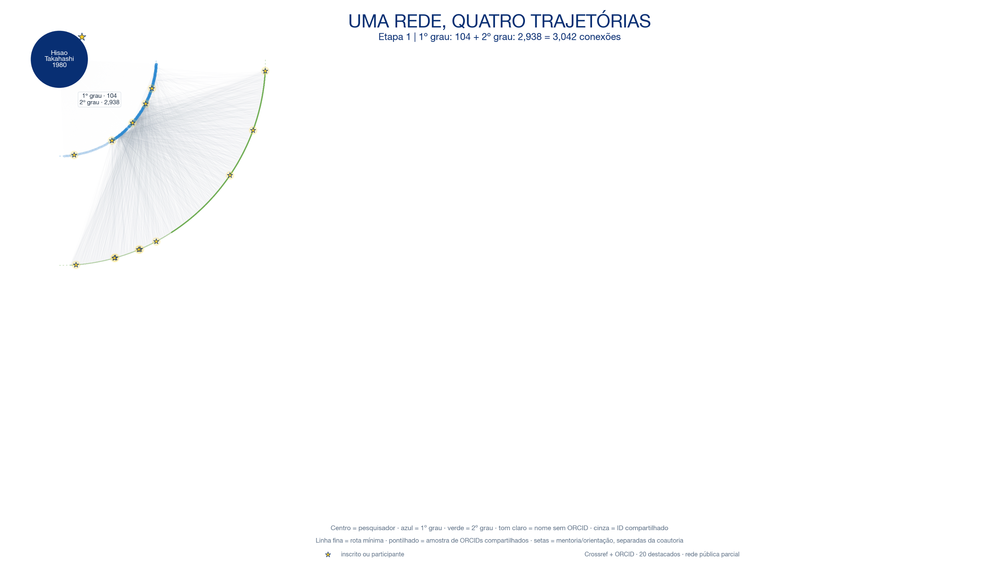

### Etapa 2 | Hisao Takahashi + Ricardo A. Buriti da Costa

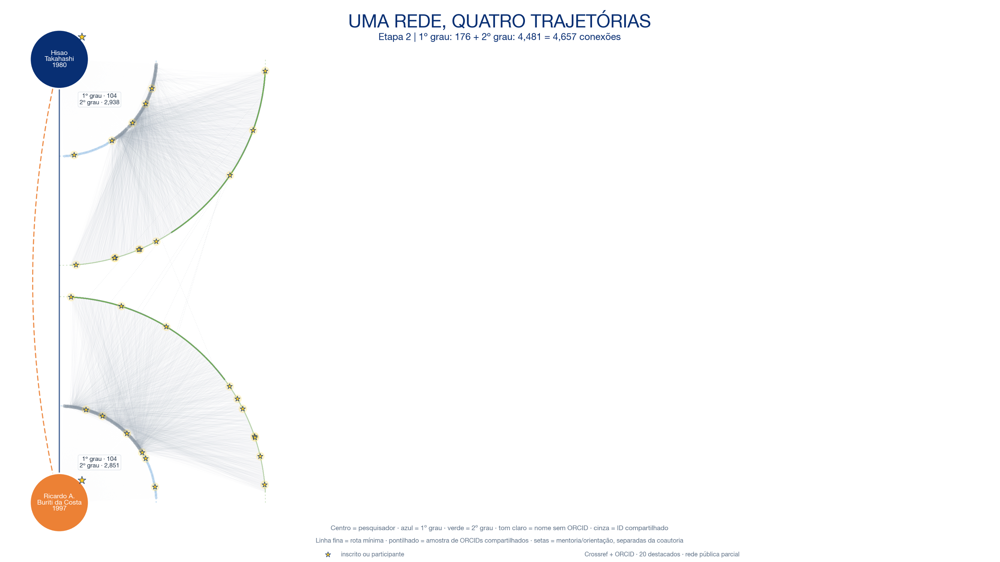

### Etapa 3 | Hisao + Ricardo + Rafael L. A. de Mesquita

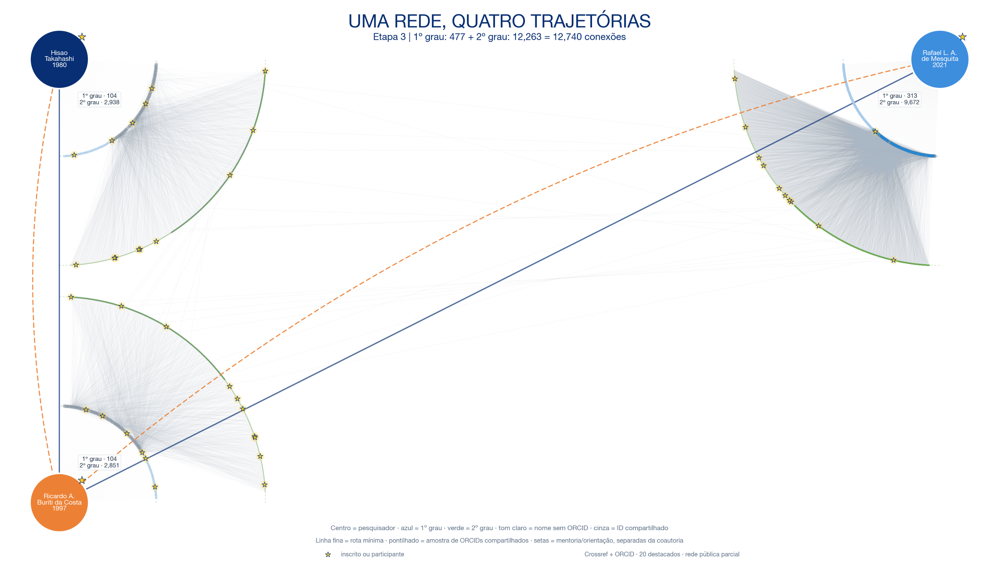

### Etapa 4 | Hisao + Ricardo + Rafael + Renato L. Sá

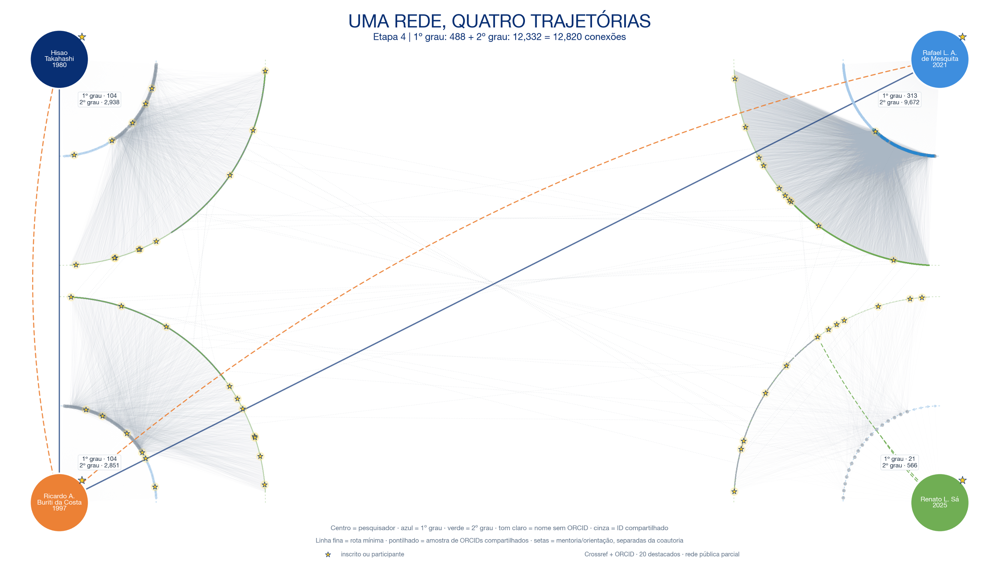

### Etapa 5 | Conexões dos participantes com os quatro centros

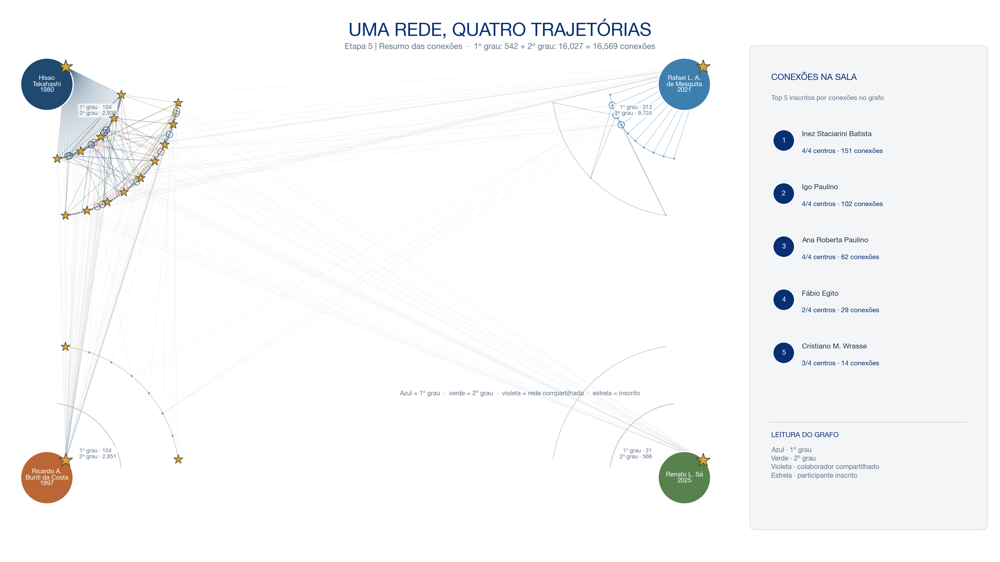

In [6]:
# Display the four full-width reveals, then the final compact summary.
for title, path in zip(FRAME_TITLES, PROGRESSIVE_FIGURES):
    display(Markdown("### " + title))
    display(Image(filename=str(path)))


### Como ler a sequência

As etapas 1–4 acrescentam um centro por vez e revelam novos pontos e ligações em cada etapa. Os quatro pesquisadores ficam nos cantos; as linhas fortes terminam nas estrelas dos centros e alcançam coautores de primeiro grau. Alguns desses colaboradores aparecem como pequenos hubs com anéis, ramificando-se para uma amostra de conexões reais de segundo grau. Cada ponto mostrado tem pelo menos uma linha visível.

A quantidade de raios, hubs intermediários, ramos por hub, linhas de contexto, espessura e transparência está reunida em `NETWORK_STYLE` na célula de renderização. Assim, a densidade da amostra e a ênfase visual podem ser ajustadas sem alterar a física nem a rede de origem.

Na etapa 5, linhas douradas destacam vínculos diretos entre os cinco inscritos mais conectados e outras pessoas da sala identificadas nos grafos. Todos os pontos dessa subrede são estrelas, com uma ocorrência por pessoa. A cobertura das fontes é parcial; ausência de linha não prova ausência de colaboração.

## Rede de coautoria inspirada no ADS

Esta figura complementa a rede dos quatro pesquisadores. Cada autor ocupa um segmento no perímetro; as cordas ligam coautores que aparecem no mesmo trabalho. O tamanho do segmento acompanha as ocorrências do nome nos resultados. O gráfico à direita mostra a atividade anual dos grupos detectados na rede. **Ninguém ocupa o centro.**

A consulta é feita por ORCID para reduzir homônimos. O caderno usa a API oficial do NASA ADS se `ADS_API_TOKEN` ou `ADS_DEV_KEY` estiver configurado; sem token, lê o cache local de resultados ADS salvo neste projeto. Se o cache não existir, usa a captura local do OpenAlex. O token nunca é gravado no caderno ou no cache.

Esta é uma visualização própria inspirada no painel de rede do ADS, não uma figura oficial do ADS. Os grupos são detectados pela estrutura de coautoria e não representam áreas temáticas. Como bases bibliográficas podem conter assinaturas variantes, somente variações do nome do pesquisador consultado são consolidadas; outros autores são mantidos por nome normalizado para evitar fusões especulativas.

Fonte ativa: NASA ADS · cache da busca por ORCID · 19 trabalhos
Trabalhos: 19 | autores normalizados: 148 | autores no anel: 34 | cordas: 181
Figura salva: $SBGEA_KEYNOTE_DATA/outputs/figures/science_network/ADS_Author_Network.png


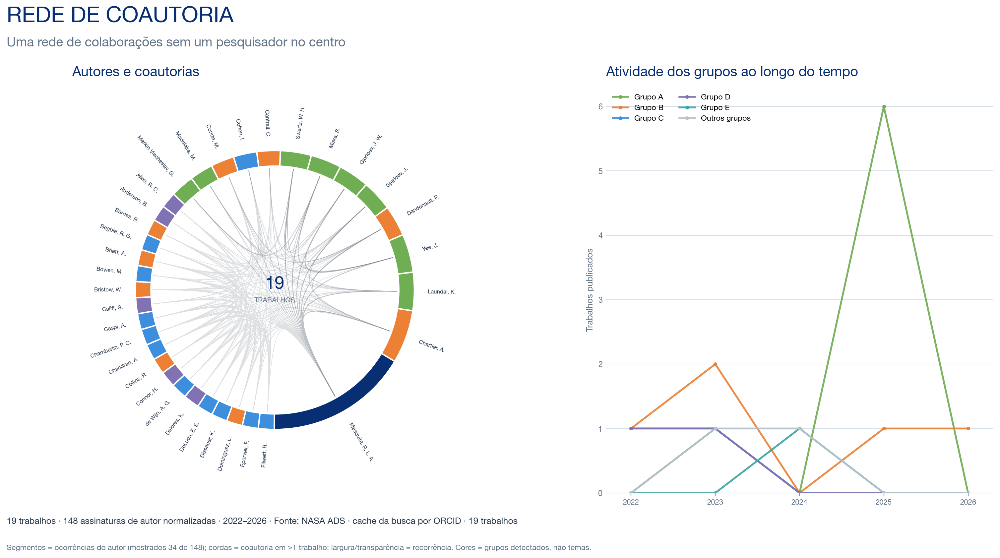

In [20]:
# ADS-inspired chord network. ADS records are cached without credentials.
from collections import Counter, defaultdict
from itertools import combinations
import json, os, re, unicodedata, urllib.parse, urllib.request
import networkx as nx
from matplotlib.patches import Wedge, PathPatch
from matplotlib.path import Path as MplPath

ADS_ORCID = "0000-0003-4681-8679"
ADS_QUERY = f"orcid:{ADS_ORCID}"
ADS_ENDPOINT = "https://api.adsabs.harvard.edu/v1/search/query"
ADS_CACHE = output_path("cache", "science_network", "ads_author_works_cache.json")
ADS_FIGURE = FIGURE_DIR / "ADS_Author_Network.png"
ADS_MAX_ROWS = 2000
ADS_MAX_AUTHORS = 34  # Includes Rafael; adjust for a denser or sparser chord ring.


def _ads_search_by_orcid(token, query=ADS_QUERY, page_size=200, max_rows=ADS_MAX_ROWS):
    """Retrieve ADS records with the official Search API and bearer token."""
    docs, start = [], 0
    fields = "bibcode,title,author,year,doi,citation_count"
    while start < max_rows:
        params = urllib.parse.urlencode({"q": query, "fl": fields, "rows": min(page_size, max_rows-start), "start": start})
        request = urllib.request.Request(
            ADS_ENDPOINT + "?" + params,
            headers={"Authorization": "Bearer " + token, "Accept": "application/json"},
        )
        with urllib.request.urlopen(request, timeout=45) as response:
            payload = json.load(response)
        page = payload.get("response", {}).get("docs", [])
        docs.extend(page)
        if len(page) < page_size:
            break
        start += len(page)
    return docs


def _clean_author_name(value):
    value = unicodedata.normalize("NFKD", str(value or ""))
    value = "".join(ch for ch in value if not unicodedata.combining(ch)).casefold()
    return re.sub(r"[^a-z0-9]+", "", value)


def _author_identity(name):
    """Collapse observed Rafael name variants from ORCID-linked ADS records."""
    pieces = str(name).split(",", 1)
    surname = _clean_author_name(pieces[0])
    given = _clean_author_name(pieces[1]) if len(pieces) > 1 else ""
    is_ra = "mesquita" in surname and (given.startswith("rafael") or given in {"r", "rl", "rla"})
    if is_ra:
        return "ROOT:rafael", "Rafael L. A. de Mesquita"
    return "AUTHOR:" + _clean_author_name(name), str(name).strip()


ADS_API_TOKEN = os.environ.get("ADS_API_TOKEN", "") or os.environ.get("ADS_DEV_KEY", "") or os.environ.get("ADS_TOKEN", "")
ads_docs = []
ADS_SOURCE = ""
if ADS_API_TOKEN:
    try:
        ads_docs = _ads_search_by_orcid(ADS_API_TOKEN)
        if ads_docs:
            ADS_CACHE.parent.mkdir(parents=True, exist_ok=True)
            ADS_CACHE.write_text(json.dumps(ads_docs, ensure_ascii=False, indent=2))
            ADS_SOURCE = f"NASA ADS · ORCID · {len(ads_docs)} trabalhos"
    except Exception as exc:
        print(f"Não foi possível atualizar o ADS ({type(exc).__name__}); tentando o cache local.")
if not ads_docs and ADS_CACHE.exists():
    ads_docs = json.loads(ADS_CACHE.read_text())
    if ads_docs:
        ADS_SOURCE = f"NASA ADS · cache da busca por ORCID · {len(ads_docs)} trabalhos"

# Fallback only when neither a live ADS response nor an ADS cache is available.
if not ads_docs:
    ads_docs = []
    for work in root_snapshot.get("results", []):
        authors = []
        for authorship in work.get("authorships", []):
            author = authorship.get("author") or {}
            name = author.get("display_name") or ""
            author_id = (author.get("id") or "").rsplit("/", 1)[-1]
            if author_id == ROOT_ID or ("rafael" in _clean_author_name(name) and "mesquita" in _clean_author_name(name)):
                name = "Araujo de Mesquita, Rafael Luiz"
            authors.append(name)
        ads_docs.append({"bibcode": work.get("doi") or work.get("id"), "title": [work.get("display_name", "")],
                         "author": authors, "year": work.get("publication_year")})
    ADS_SOURCE = f"OpenAlex · captura local · {len(ads_docs)} trabalhos"

# Convert to deduplicated publication records and author identities.
works = {}
for doc in ads_docs:
    bibcode = str(doc.get("bibcode") or doc.get("doi") or (doc.get("year"), doc.get("title")))
    author_names = doc.get("author") or []
    if isinstance(author_names, str):
        author_names = [author_names]
    authors = {}
    for name in author_names:
        key, label = _author_identity(name)
        authors.setdefault(key, label)
    if not any(k == "ROOT:rafael" for k in authors):
        # ADS ORCID queries may omit the matching signature in the returned author list;
        # the ORCID-linked record still establishes the query identity for that paper.
        authors["ROOT:rafael"] = "Rafael L. A. de Mesquita"
    raw_year = doc.get("year")
    try:
        year = int(str(raw_year)[:4])
    except (TypeError, ValueError):
        year = None
    works.setdefault(bibcode, {"authors": authors, "year": year, "title": doc.get("title", "")})

root_node = "ROOT:rafael"
assert works, "No ADS/OpenAlex records were found."

# Build weighted coauthorship edges: weight is the count of shared papers.
G_chord = nx.Graph()
author_labels = {root_node: "Rafael L. A. de Mesquita"}
author_occurrences = Counter()
edge_weights = Counter()
works_for_activity = []
for work in works.values():
    author_labels.update(work["authors"])
    ids = sorted(work["authors"])
    author_occurrences.update(ids)
    works_for_activity.append((work["year"], ids))
    for u, v in combinations(ids, 2):
        edge_weights[(u, v)] += 1
G_chord.add_nodes_from(author_occurrences)
for (u, v), weight in edge_weights.items():
    G_chord.add_edge(u, v, weight=weight)

# Detect collaborator groups without using the focal author as a hub in clustering.
collaborator_graph = G_chord.subgraph([n for n in G_chord if n != root_node]).copy()
if collaborator_graph.number_of_edges():
    communities = list(nx.community.greedy_modularity_communities(collaborator_graph, weight="weight"))
else:
    communities = [{n} for n in collaborator_graph.nodes]
communities = sorted(communities, key=lambda group: (-len(group), sorted(group)[0] if group else ""))
community_of = {node: i for i, group in enumerate(communities) for node in group}

# Keep the most frequently occurring names, including Rafael as a normal ring segment.
all_authors = sorted(author_occurrences, key=lambda n: (-author_occurrences[n], author_labels[n].casefold(), n))
selected_authors = all_authors[:ADS_MAX_AUTHORS]
selected_set = set(selected_authors)

# Assign every paper to its most represented coauthor community for the activity panel.
community_work_counts = Counter()
for year, ids in works_for_activity:
    if year is None:
        continue
    votes = Counter(community_of[n] for n in ids if n != root_node and n in community_of)
    if votes:
        community_work_counts[votes.most_common(1)[0][0]] += 1
major_groups = [group for group, _ in community_work_counts.most_common(5)]
palette = ["#3E8EDE", "#70AE54", "#EC8135", "#8172B3", "#39A6A3", "#D46A86", "#607D8B"]
other_color = "#B8C2CC"
community_color = {group: palette[i % len(palette)] for i, group in enumerate(sorted(set(community_of.values())))}

# Circular chord layout. Segment length is proportional to author occurrences.
ring_gap = np.deg2rad(0.45)
weights = np.array([author_occurrences[n] for n in selected_authors], dtype=float)
angle_spans = (2*np.pi - ring_gap*len(selected_authors)) * weights / weights.sum()
angles, sectors = {}, {}
angle = -np.pi/2
for node, span in zip(selected_authors, angle_spans):
    start, end = angle, angle + span
    sectors[node] = (start, end)
    angles[node] = (start + end)/2
    angle = end + ring_gap

# Create a wide slide canvas before drawing any artists.
fig_chord = plt.figure(figsize=(16, 9), dpi=200, facecolor="white")
gs_chord = fig_chord.add_gridspec(1, 2, width_ratios=[1.18, 0.82], left=0.035, right=0.975, top=0.82, bottom=0.14, wspace=0.11)
ax_chord = fig_chord.add_subplot(gs_chord[0, 0])
ax_activity = fig_chord.add_subplot(gs_chord[0, 1])

# Draw coauthor chords as one batched set of cubic Bezier paths for a light, clean interior.
chord_bins = defaultdict(list)
for (u, v), shared_count in edge_weights.items():
    if u not in selected_set or v not in selected_set:
        continue
    a1, a2 = angles[u], angles[v]
    p0 = np.array([0.88*np.cos(a1), 0.88*np.sin(a1)])
    p3 = np.array([0.88*np.cos(a2), 0.88*np.sin(a2)])
    p1, p2 = 0.12*p0, 0.12*p3
    chord_bins[min(shared_count, 4)].append((p0, p1, p2, p3))
for shared_count, curves in chord_bins.items():
    vertices, codes = [], []
    for p0, p1, p2, p3 in curves:
        vertices.extend([p0, p1, p2, p3])
        codes.extend([MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4])
    alpha = {1: 0.12, 2: 0.19, 3: 0.27, 4: 0.36}.get(shared_count, 0.43)
    linewidth = 0.34 + 0.12*min(shared_count, 4)
    ax_color = "#4B5563"
    chord_path = MplPath(np.asarray(vertices), np.asarray(codes))
    ax_chord.add_patch(PathPatch(chord_path, facecolor="none", edgecolor=ax_color, linewidth=linewidth, alpha=alpha, zorder=1))

# Annular author segments, colored by collaboration community; Rafael is on the ring too.
for node in selected_authors:
    start, end = sectors[node]
    if node == root_node:
        color = COLORS["navy"]
    else:
        color = community_color.get(community_of.get(node), other_color)
    ax_chord.add_patch(Wedge((0, 0), 1.0, np.rad2deg(start), np.rad2deg(end), width=0.105,
                             facecolor=color, edgecolor="white", linewidth=0.45, zorder=3))

# Radial labels use compact initials to keep the complete perimeter legible.
def _compact_ads_name(name, node):
    if node == root_node:
        return "Mesquita, R. L. A."
    parts = str(name).split(",", 1)
    if len(parts) == 1:
        return str(name)
    family, given = parts[0].strip(), parts[1].strip()
    initials = " ".join(token[0].upper()+"." for token in given.split() if token and token[0].isalnum())
    if len(family) > 19:
        family = family.split()[-1]
    return f"{family}, {initials}" if initials else family

for node in selected_authors:
    mid = angles[node]
    degrees = np.rad2deg(mid)
    x, y = 1.10*np.cos(mid), 1.10*np.sin(mid)
    rotation = degrees
    ha = "left"
    if 90 < degrees < 270:
        rotation += 180
        ha = "right"
    ax_chord.text(x, y, _compact_ads_name(author_labels[node], node), rotation=rotation,
                  rotation_mode="anchor", ha=ha, va="center", fontsize=6.0 if len(selected_authors) > 28 else 6.7,
                  color=COLORS["ink"], clip_on=False, zorder=5)

# Center is deliberately unassigned to a person.
ax_chord.text(0, 0.045, f"{len(works)}", ha="center", va="center", color=COLORS["navy"], fontsize=19, fontweight="bold")
ax_chord.text(0, -0.075, "TRABALHOS", ha="center", va="center", color=COLORS["muted"], fontsize=7.5, fontweight="bold")
ax_chord.set_xlim(-1.46, 1.46); ax_chord.set_ylim(-1.46, 1.46)
ax_chord.set_aspect("equal"); ax_chord.axis("off")

# Group activity by year, using discrete observations rather than smoothing the data.
activity = defaultdict(Counter)
for year, ids in works_for_activity:
    if year is None:
        continue
    votes = Counter(community_of[n] for n in ids if n != root_node and n in community_of)
    if votes:
        group = votes.most_common(1)[0][0]
        activity[group if group in major_groups else "Outros"] += Counter({year: 1})
all_years = sorted({year for year, _ in works_for_activity if year is not None})
if all_years:
    years = np.arange(min(all_years), max(all_years)+1)
    plotted_groups = major_groups + (["Outros"] if any(activity["Outros"].values()) else [])
    for rank, group in enumerate(plotted_groups):
        counts = np.array([activity[group].get(int(year), 0) for year in years])
        color = other_color if group == "Outros" else community_color[group]
        label = "Outros grupos" if group == "Outros" else f"Grupo {chr(65+rank)}"
        ax_activity.plot(years, counts, color=color, lw=2.0, marker="o", markersize=3.0, alpha=0.92, label=label)
    ax_activity.set_xlim(years.min()-0.3, years.max()+0.3)
    ax_activity.set_ylim(bottom=0)
    ax_activity.set_xticks(years[::2] if len(years) > 12 else years)
    ax_activity.tick_params(axis="x", labelrotation=0, labelsize=8, colors=COLORS["muted"])
    ax_activity.tick_params(axis="y", labelsize=8.5, colors=COLORS["muted"], length=0)
    ax_activity.set_ylabel("Trabalhos publicados", fontsize=9.5, color=COLORS["muted"])
    ax_activity.grid(axis="y", color=COLORS["line"], lw=0.7)
    ax_activity.spines[["top", "right", "left"]].set_visible(False)
    ax_activity.spines["bottom"].set_color(COLORS["line"])
    ax_activity.set_axisbelow(True)
    ax_activity.legend(frameon=False, fontsize=8.4, ncol=2, loc="upper left")

# Titles, notes, and the exported slide-size image.
fig_chord.text(0.045, 0.955, "REDE DE COAUTORIA", color=COLORS["navy"], fontsize=24, fontweight="bold", ha="left", va="top")
fig_chord.text(0.045, 0.905, "Uma rede de colaborações sem um pesquisador no centro", color=COLORS["muted"], fontsize=14, ha="left", va="top")
ax_chord.set_title("Autores e coautorias", loc="left", color=COLORS["navy"], fontsize=15, fontweight="bold", pad=12)
ax_activity.set_title("Atividade dos grupos ao longo do tempo", loc="left", color=COLORS["navy"], fontsize=15, fontweight="bold", pad=12)
all_year_values = [year for year, _ in works_for_activity if year is not None]
period = f"{min(all_year_values)}–{max(all_year_values)}" if all_year_values else "período não informado"
fig_chord.text(0.045, 0.092,
    f"{len(works)} trabalhos · {len(all_authors)} assinaturas de autor normalizadas · {period} · Fonte: {ADS_SOURCE}",
    color=COLORS["ink"], fontsize=9.6, ha="left", va="center")
fig_chord.text(0.045, 0.048,
    f"Segmentos = ocorrências do autor (mostrados {len(selected_authors)} de {len(all_authors)}); cordas = coautoria em ≥1 trabalho; largura/transparência = recorrência. Cores = grupos detectados, não temas.",
    color=COLORS["muted"], fontsize=8.3, ha="left", va="center")
fig_chord.savefig(ADS_FIGURE, dpi=200, facecolor="white")
print(f"Fonte ativa: {ADS_SOURCE}")
print(f"Trabalhos: {len(works)} | autores normalizados: {len(all_authors)} | autores no anel: {len(selected_authors)} | cordas: {sum(len(v) for v in chord_bins.values())}")
print(f"Figura salva: {ADS_FIGURE}")
plt.show()


## Síntese: uma rede, quatro trajetórias

Este quadro combina a leitura circular do ADS com a história dos quatro pesquisadores. Hisao Takahashi, Ricardo A. Buriti da Costa, Rafael L. A. de Mesquita e Renato L. Sá aparecem como quatro âncoras na circunferência, sem um centro único. Cada colaborador aparece uma vez; segmentos divididos indicam em quais redes ele está presente, e as cordas mostram ligações bibliográficas. Estrelas destacam inscritos identificados.

O painel lateral mostra o ano de doutorado informado para cada trajetória e quantos coautores diretos são compartilhados por cada par. A figura usa as mesmas redes ORCID/Crossref e o enriquecimento Google Scholar já carregados acima. Para manter a leitura clara, ela inclui todos os coautores diretos compartilhados, participantes inscritos alcançáveis em até dois passos e uma amostra configurável de coautores exclusivos. As ligações desenhadas são relações registradas nas fontes; nomes sem identificador não são unidos por correspondência aproximada.


Figura integrada salva: $SBGEA_KEYNOTE_DATA/outputs/figures/science_network/Four_Trajectories_Combined_Chord.png
Exibidos: 88 pessoas | compartilhadas diretamente: 52 | estrelas: 20 | cordas: 284


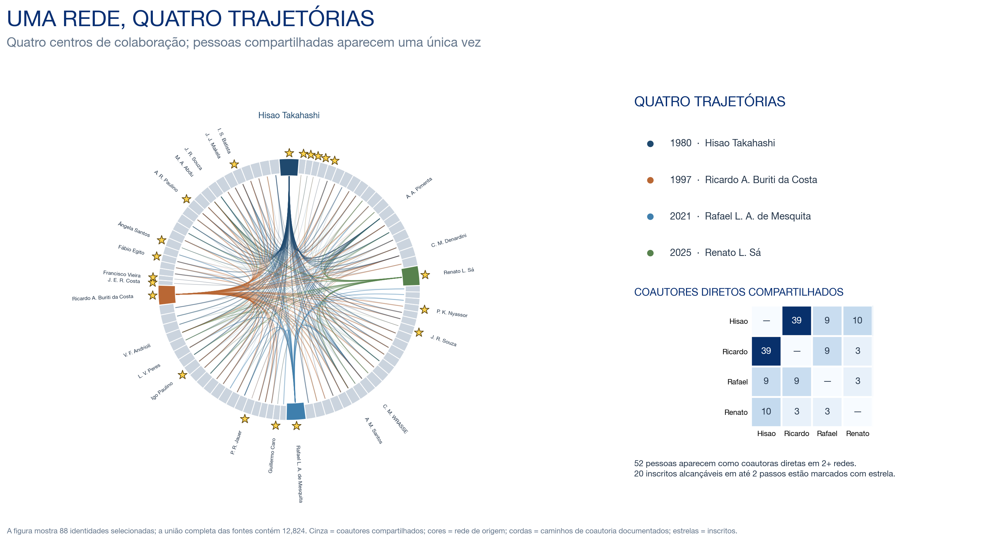

In [21]:
# A single circular synthesis of the four existing coauthor networks.
# Each identity appears once; shared people receive a multi-color perimeter segment.
from collections import Counter, defaultdict
from itertools import combinations
from matplotlib.collections import LineCollection
from matplotlib.patches import Wedge, PathPatch
from matplotlib.path import Path as CombinedPath

COMBINED_FIGURE = FIGURE_DIR / "Four_Trajectories_Combined_Chord.png"
COMBINED_STYLE = {
    "exclusive_authors_per_anchor": 5,     # Raise this to include more unique first-degree collaborators.
    "context_edges_per_anchor": 8,         # Actual non-anchor coauthor links shown as fine chords.
    "shared_label_limit": 10,
    "ring_gap_degrees": 0.24,
    "star_size": 105,
    "star_zorder": 60,
    "anchor_sector_weight": 8.0,
}
COMBINED_ROOTS = list(FRAME_ROOTS)
COMBINED_ROOT_NODES = {key: ANCHOR_NODE_KEYS[key] for key in COMBINED_ROOTS}
COMBINED_COLORS = {a["key"]: a["color"] for a in ANCHORS}

# First-degree collaborators and two-step reachability from the four anchor researchers.
direct_people = {key: set(FULL_GRAPH.neighbors(COMBINED_ROOT_NODES[key])) for key in COMBINED_ROOTS}
reach_two = {key: nx.single_source_shortest_path_length(FULL_GRAPH, COMBINED_ROOT_NODES[key], cutoff=2) for key in COMBINED_ROOTS}
direct_membership = defaultdict(set)
reach_membership = defaultdict(set)
for key in COMBINED_ROOTS:
    for person in direct_people[key]:
        direct_membership[person].add(key)
    for person in reach_two[key]:
        reach_membership[person].add(key)

# Keep all shared direct collaborators and the attendees already resolved in the notebook.
shared_direct_people = {p for p, roots in direct_membership.items() if len(roots) >= 2}
room_people_in_range = {p for p in ATTENDEE_PEOPLE if p in FULL_GRAPH and p in reach_membership}
selected_combined = set(COMBINED_ROOT_NODES.values()) | shared_direct_people | room_people_in_range

# Add a small, configurable sample of exclusive first-degree coauthors for each anchor.
for key in COMBINED_ROOTS:
    exclusive = [p for p in direct_people[key] if direct_membership[p] == {key}]
    exclusive.sort(key=lambda p: (-FULL_GRAPH.degree(p), attendee_name(p).casefold(), p))
    selected_combined.update(exclusive[:COMBINED_STYLE["exclusive_authors_per_anchor"]])

# Add the actual shortest-path bridge nodes needed to connect every selected person to each
# anchor network in which they occur within two steps.
required_paths = defaultdict(set)
for person in list(selected_combined):
    if person in COMBINED_ROOT_NODES.values():
        continue
    for key in reach_membership.get(person, set()):
        try:
            path = nx.shortest_path(FULL_GRAPH, COMBINED_ROOT_NODES[key], person)
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            continue
        selected_combined.update(path)
        for u, v in zip(path[:-1], path[1:]):
            required_paths[tuple(sorted((u, v)))].add(key)

# Name labels are collected from the same source graphs already reconciled above.
combined_name_by_person = defaultdict(set)
for key in COMBINED_ROOTS:
    source_graph = ORCID_NETWORKS[key]["graph"]
    for source_node in source_graph.nodes:
        canonical = person_key(source_node)
        combined_name_by_person[canonical].update(node_display_names.get(source_node, set()))
for key, root_node in COMBINED_ROOT_NODES.items():
    combined_name_by_person[root_node] = {ANCHOR_BY_KEY[key]["display"]}
for person, names in ATTENDEE_NAMES_BY_PERSON.items():
    combined_name_by_person[person].update(names)

# Determine each person's network membership within two steps; these memberships color
# the one sector assigned to that person.
combined_membership = {p: set(reach_membership.get(p, set())) for p in selected_combined}
for key, root_node in COMBINED_ROOT_NODES.items():
    combined_membership[root_node] = {key}
combined_membership = {p: roots for p, roots in combined_membership.items() if roots}
selected_combined = set(combined_membership)
combined_attendees = room_people_in_range & selected_combined
combined_attendees.update(set(COMBINED_ROOT_NODES.values()) & set(ATTENDEE_PEOPLE))

# Choose a balanced four-part circular order. Shared identities stay single but are
# assigned to one visual sector; their wedge itself is split by network membership.
sector_people = {key: [] for key in COMBINED_ROOTS}
network_load = Counter()
nonanchors = [p for p in selected_combined if p not in COMBINED_ROOT_NODES.values()]
nonanchors.sort(key=lambda p: (-len(combined_membership[p]), -FULL_GRAPH.degree(p), p))
for person in nonanchors:
    choices = sorted(combined_membership[person], key=lambda k: (network_load[k], COMBINED_ROOTS.index(k)))
    primary = choices[0]
    sector_people[primary].append(person)
    network_load[primary] += 1 + 0.65*(len(combined_membership[person])-1)
combined_ring_order = []
for key in COMBINED_ROOTS:
    combined_ring_order.append(COMBINED_ROOT_NODES[key])
    sector_people[key].sort(key=lambda p: (-len(combined_membership[p]), -FULL_GRAPH.degree(p), p))
    combined_ring_order.extend(sector_people[key])

# Add informative labels for all anchors, linked attendees, and the most connected bridges.
shared_ranked = sorted(shared_direct_people & selected_combined,
                       key=lambda p: (-len(direct_membership[p]), -FULL_GRAPH.degree(p), p))
label_nodes = set(COMBINED_ROOT_NODES.values()) | combined_attendees | set(shared_ranked[:COMBINED_STYLE["shared_label_limit"]])

# Sector width grows with cross-network membership; the four anchors are prominent perimeter hubs.
sector_weights = []
for person in combined_ring_order:
    if person in COMBINED_ROOT_NODES.values():
        sector_weights.append(COMBINED_STYLE["anchor_sector_weight"])
    else:
        sector_weights.append(1.0 + 0.72*(len(combined_membership[person])-1) + 0.10*np.log1p(FULL_GRAPH.degree(person)))
sector_weights = np.asarray(sector_weights, dtype=float)
ring_gap = np.deg2rad(COMBINED_STYLE["ring_gap_degrees"])
available_angle = 2*np.pi - ring_gap*len(combined_ring_order)
spans = available_angle * sector_weights / sector_weights.sum()
sector_angles = {}
sector_bounds = {}
angle = np.pi/2 - spans[0]/2  # Center Hisao Takahashi at the top of the circle.
for person, span in zip(combined_ring_order, spans):
    sector_bounds[person] = (angle, angle+span)
    sector_angles[person] = angle + span/2
    angle += span + ring_gap

# Required paths color each anchor-to-collaborator chord. Add a fixed sample of actual
# secondary coauthor links to reveal cross-network structure without filling the circle.
combined_edge_roots = defaultdict(set)
for edge, roots in required_paths.items():
    combined_edge_roots[edge].update(roots)
anchor_node_set = set(COMBINED_ROOT_NODES.values())
for key in COMBINED_ROOTS:
    candidates = []
    for edge in ROOT_CANONICAL_EDGE_SETS[key]:
        u, v = edge
        if u in selected_combined and v in selected_combined and u not in anchor_node_set and v not in anchor_node_set and edge not in combined_edge_roots:
            candidates.append(edge)
    candidates = sorted(candidates)
    if candidates:
        rng = np.random.default_rng(NETWORK_STYLE["context_seed"] + COMBINED_ROOTS.index(key) + 44)
        take = min(COMBINED_STYLE["context_edges_per_anchor"], len(candidates))
        chosen = np.sort(rng.choice(len(candidates), size=take, replace=False))
        for index in chosen:
            combined_edge_roots[candidates[index]].add(key)

# Build the combined slide: chord network at left, four trajectories and overlap matrix at right.
fig_combined = plt.figure(figsize=(16, 9), dpi=200, facecolor="white")
gs_combined = fig_combined.add_gridspec(1, 2, width_ratios=[1.24, 0.76], left=0.035, right=0.975, top=0.82, bottom=0.14, wspace=0.11)
ax_combined_net = fig_combined.add_subplot(gs_combined[0, 0])
ax_combined_info = fig_combined.add_subplot(gs_combined[0, 1])

# Draw curved chords, with anchor colors for each documented route.
for edge, roots in combined_edge_roots.items():
    u, v = edge
    if u not in sector_angles or v not in sector_angles:
        continue
    a1, a2 = sector_angles[u], sector_angles[v]
    p0 = np.array([0.88*np.cos(a1), 0.88*np.sin(a1)])
    p3 = np.array([0.88*np.cos(a2), 0.88*np.sin(a2)])
    path = CombinedPath([p0, 0.14*p0, 0.14*p3, p3],
                        [CombinedPath.MOVETO, CombinedPath.CURVE4, CombinedPath.CURVE4, CombinedPath.CURVE4])
    root_end = next((key for key, node in COMBINED_ROOT_NODES.items() if node in edge), None)
    if root_end:
        edge_color, lw, alpha, zorder = COMBINED_COLORS[root_end], 0.95, 0.48, 3
    elif len(roots) > 1:
        edge_color, lw, alpha, zorder = "#35465A", 0.60, 0.34, 2
    else:
        edge_color, lw, alpha, zorder = COMBINED_COLORS[next(iter(roots))], 0.48, 0.24, 2
    ax_combined_net.add_patch(PathPatch(path, facecolor="none", edgecolor=edge_color,
                                        linewidth=lw, alpha=alpha, zorder=zorder))

# Draw each author once. Shared identities have one sector split into colored sub-arcs.
for person in combined_ring_order:
    start, end = sector_bounds[person]
    if person in COMBINED_ROOT_NODES.values():
        anchor_key = next(key for key, node in COMBINED_ROOT_NODES.items() if node == person)
        color = COMBINED_COLORS[anchor_key]
        ax_combined_net.add_patch(Wedge((0,0), 1.0, np.rad2deg(start), np.rad2deg(end), width=0.13,
                                        facecolor=color, edgecolor="white", linewidth=0.7, zorder=5))
    else:
        roots = sorted(combined_membership[person], key=COMBINED_ROOTS.index)
        # Shared people keep one sector; the network color is carried by their chords.
        color = COMBINED_COLORS[roots[0]] if len(roots) == 1 else "#CBD4DE"
        ax_combined_net.add_patch(Wedge((0,0), 1.0, np.rad2deg(start), np.rad2deg(end), width=0.11,
                                        facecolor=color, edgecolor="white", linewidth=0.35, zorder=5))

# Bright participant stars sit above all chord and ring artists.
star_nodes = [p for p in combined_attendees if p in sector_angles]
if star_nodes:
    xy = np.asarray([[1.045*np.cos(sector_angles[p]), 1.045*np.sin(sector_angles[p])] for p in star_nodes])
    ax_combined_net.scatter(xy[:,0], xy[:,1], s=COMBINED_STYLE["star_size"], marker="*", color="#FFD34E",
                            edgecolors="#604A13", linewidths=0.75, zorder=COMBINED_STYLE["star_zorder"])

# Radial labels are abbreviated for fit; full anchor and attendee names are in the side panel or source table.
def _combined_label(person):
    if person in COMBINED_ROOT_NODES.values():
        key = next(k for k, node in COMBINED_ROOT_NODES.items() if node == person)
        return ANCHOR_BY_KEY[key]["display"]
    names = combined_name_by_person.get(person, set())
    full = attendee_name(person) if person in ATTENDEE_NAMES_BY_PERSON else (sorted(names)[0] if names else person)
    parts = str(full).replace(",", " ").split()
    if len(parts) <= 2:
        return " ".join(parts)
    return " ".join([p[0].upper()+"." for p in parts[:-1] if p] + [parts[-1]])

hisao_root_node = COMBINED_ROOT_NODES[COMBINED_ROOTS[0]]
for person in label_nodes:
    if person not in sector_angles or person == hisao_root_node:
        continue
    theta = sector_angles[person]
    # Reserve the 12-o'clock label area for Hisao; nearby attendee stars remain visible,
    # but their names are omitted there to prevent a collision.
    top_distance = abs((theta - np.pi/2 + np.pi) % (2*np.pi) - np.pi)
    if top_distance < np.deg2rad(22):
        continue
    degrees = np.rad2deg(theta) % 360
    rot = degrees
    ha = "left"
    if 90 < degrees < 270:
        rot += 180
        ha = "right"
    label = _combined_label(person)
    r = 1.14 if person not in COMBINED_ROOT_NODES.values() else 1.19
    ax_combined_net.text(r*np.cos(theta), r*np.sin(theta), label, rotation=rot, rotation_mode="anchor",
                         ha=ha, va="center", fontsize=5.7 if len(combined_ring_order)>65 else 6.3,
                         color=COLORS["ink"], clip_on=False, zorder=20)
ax_combined_net.text(0, 1.30, "Hisao Takahashi", ha="center", va="bottom", color=COMBINED_COLORS[COMBINED_ROOTS[0]],
                     fontsize=9.2, fontweight="bold", clip_on=False, zorder=25)
ax_combined_net.set_xlim(-1.55, 1.55); ax_combined_net.set_ylim(-1.55, 1.55)
ax_combined_net.set_aspect("equal"); ax_combined_net.axis("off")

# Right panel: the four doctorate-year trajectories and a direct-collaborator overlap matrix.
ax_combined_info.axis("off")
ax_combined_info.text(0.0, 0.98, "QUATRO TRAJETÓRIAS", transform=ax_combined_info.transAxes,
                      color=COLORS["navy"], fontsize=15, fontweight="bold", ha="left", va="top")
for idx, key in enumerate(COMBINED_ROOTS):
    anchor = ANCHOR_BY_KEY[key]
    y = 0.86 - idx*0.09
    ax_combined_info.scatter([0.045], [y], transform=ax_combined_info.transAxes, s=60,
                             color=COMBINED_COLORS[key], edgecolors="white", linewidths=0.7, zorder=3)
    ax_combined_info.text(0.10, y, f"{anchor['year']}  ·  {anchor['display']}", transform=ax_combined_info.transAxes,
                          color=COLORS["ink"], fontsize=10.5, ha="left", va="center")
ax_combined_info.text(0.0, 0.48, "COAUTORES DIRETOS COMPARTILHADOS", transform=ax_combined_info.transAxes,
                      color=COLORS["navy"], fontsize=11.3, fontweight="bold", ha="left", va="bottom")
short_names = ["Hisao", "Ricardo", "Rafael", "Renato"]
overlap = np.zeros((4,4), dtype=int)
for i, key_a in enumerate(COMBINED_ROOTS):
    for j, key_b in enumerate(COMBINED_ROOTS):
        if i != j:
            overlap[i,j] = len(direct_people[key_a] & direct_people[key_b])
ax_matrix = ax_combined_info.inset_axes([0.04, 0.16, 0.91, 0.30])
ax_matrix.imshow(overlap, cmap="Blues", vmin=0, vmax=max(1,int(overlap.max())))
ax_matrix.set_xticks(range(4), short_names, fontsize=8)
ax_matrix.set_yticks(range(4), short_names, fontsize=8)
ax_matrix.tick_params(length=0)
ax_matrix.set_xticks(np.arange(-.5,4,1), minor=True); ax_matrix.set_yticks(np.arange(-.5,4,1), minor=True)
ax_matrix.grid(which="minor", color="white", linewidth=2)
ax_matrix.tick_params(which="minor", bottom=False, left=False)
for i in range(4):
    for j in range(4):
        text = "—" if i == j else str(overlap[i,j])
        color = "white" if overlap[i,j] >= max(1, overlap.max()*0.55) and i != j else COLORS["ink"]
        ax_matrix.text(j, i, text, ha="center", va="center", color=color, fontsize=10, fontweight="bold")
for spine in ax_matrix.spines.values(): spine.set_visible(False)

shared_count = len(shared_direct_people)
room_count = len(star_nodes)
ax_combined_info.text(0.0, 0.035,
    f"{shared_count} pessoas aparecem como coautoras diretas em 2+ redes.\n{room_count} inscritos alcançáveis em até 2 passos estão marcados com estrela.",
    transform=ax_combined_info.transAxes, color=COLORS["ink"], fontsize=9.0, ha="left", va="bottom", linespacing=1.4)

fig_combined.text(0.045, 0.955, "UMA REDE, QUATRO TRAJETÓRIAS", color=COLORS["navy"], fontsize=24, fontweight="bold", ha="left", va="top")
fig_combined.text(0.045, 0.905, "Quatro centros de colaboração; pessoas compartilhadas aparecem uma única vez", color=COLORS["muted"], fontsize=14, ha="left", va="top")
fig_combined.text(0.045, 0.075,
    f"A figura mostra {len(combined_ring_order)} identidades selecionadas; a união completa das fontes contém {len(FULL_GRAPH):,}. Cinza = coautores compartilhados; cores = rede de origem; cordas = caminhos de coautoria documentados; estrelas = inscritos.",
    color=COLORS["muted"], fontsize=8.1, ha="left", va="center")
fig_combined.savefig(COMBINED_FIGURE, dpi=200, facecolor="white")
print(f"Figura integrada salva: {COMBINED_FIGURE}")
print(f"Exibidos: {len(combined_ring_order)} pessoas | compartilhadas diretamente: {shared_count} | estrelas: {room_count} | cordas: {len(combined_edge_roots)}")
plt.show()


### Anel central progressivo

Esta vista complementar coloca os pesquisadores no anel central e acrescenta cada rede na mesma ordem das quatro etapas. O primeiro anel externo mostra coautores diretos; o segundo mostra caminhos via um intermediário. Colaboradores compartilhados podem aparecer em mais de um setor, ligados por uma ponte tracejada, para deixar a interconectividade visível. A figura de resumo existente continua acima.

Etapa 1: 50 identidades únicas, 50 ocorrências em redes, 0 compartilhadas.


### Etapa 1 — Hisao Takahashi

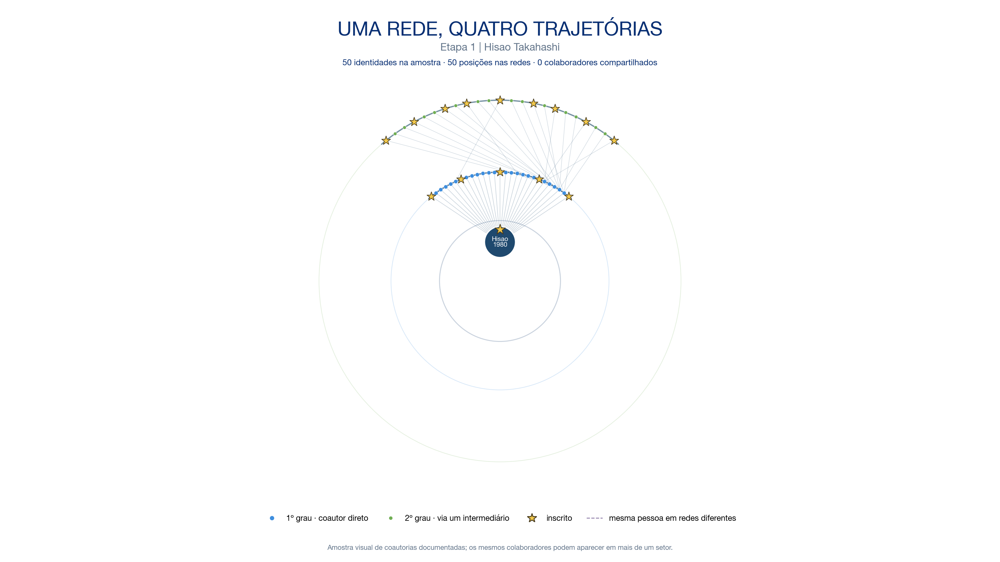

Etapa 2: 73 identidades únicas, 104 ocorrências em redes, 31 compartilhadas.


### Etapa 2 — Hisao Takahashi + Ricardo A. Buriti da Costa

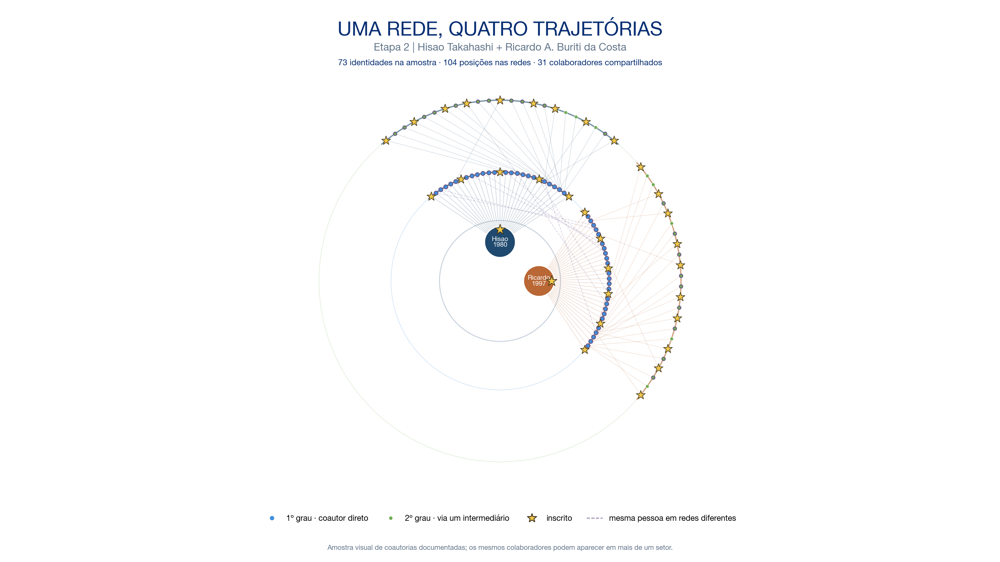

Etapa 3: 94 identidades únicas, 147 ocorrências em redes, 42 compartilhadas.


### Etapa 3 — Hisao Takahashi + Ricardo + Rafael L. A. de Mesquita

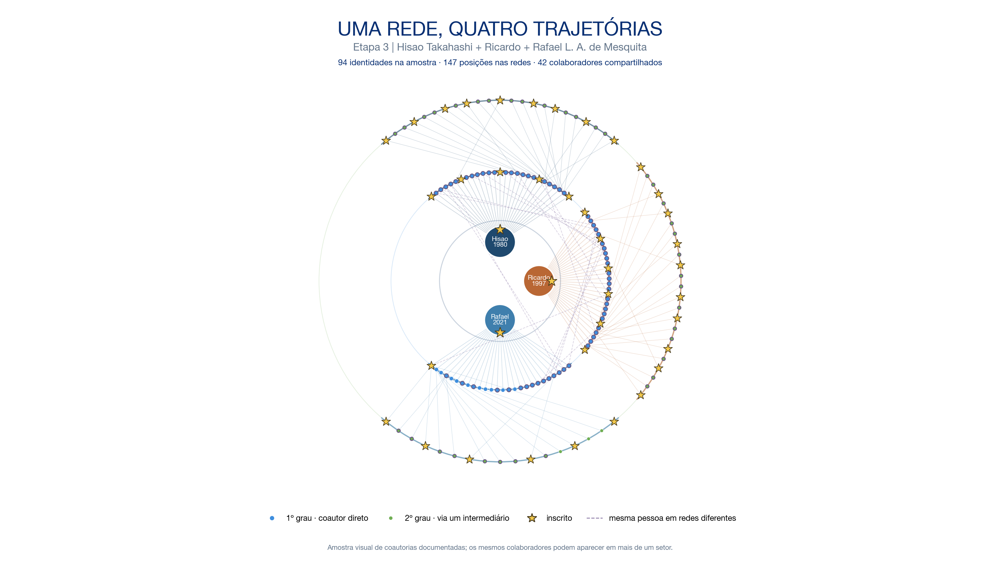

Etapa 4: 106 identidades únicas, 180 ocorrências em redes, 45 compartilhadas.


### Etapa 4 — Hisao Takahashi + Ricardo + Rafael + Renato L. Sá

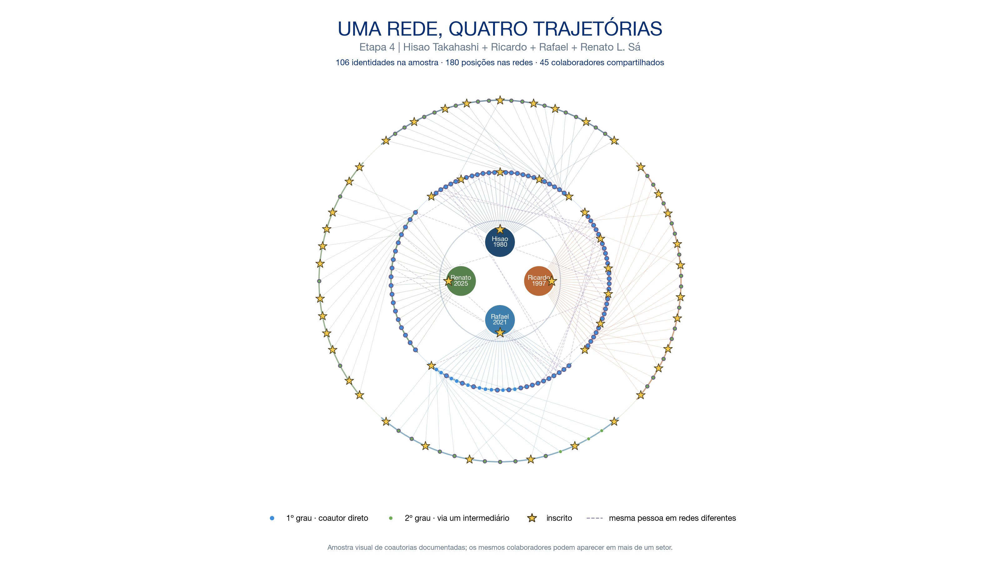

Quatro quadros progressivos do anel central salvos: ['ScienceNetwork_CentralRing_01_Hisao.png', 'ScienceNetwork_CentralRing_02_Hisao_Ricardo.png', 'ScienceNetwork_CentralRing_03_Hisao_Ricardo_Rafael.png', 'ScienceNetwork_CentralRing_04_Quatro_Pesquisadores.png']


In [7]:
# Progressive central-ring collaboration view.
# Hubs enter in the same order as the four established reveal figures.
from collections import defaultdict, Counter
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle
from IPython.display import display, Image, Markdown

CENTRAL_RING_STYLE = {
    "direct_sample_per_researcher": 18,
    "shared_direct_sample": 14,
    "branch_hubs_per_researcher": 4,
    "children_per_branch_hub": 5,
    "direct_radius": 2.18,
    "second_radius": 3.62,
    "hub_radius": 0.78,
    "hub_marker_radius": 0.31,
    "sector_half_width_deg": 41,
    "direct_size": 21,
    "second_size": 15,
    "attendee_star_size": 115,
    "hub_star_size": 155,
    "spoke_width": 0.60,
    "spoke_alpha": 0.25,
    "branch_width": 0.50,
    "branch_alpha": 0.22,
    "shared_bridge_limit": 14,
}
CENTRAL_ROOT_ORDER = list(FRAME_ROOTS)
CENTRAL_ROOT_ANGLES = {
    "Hisao Takahashi": 90.0,
    "Ricardo Arlen Buriti da Costa": 0.0,
    "Rafael Luiz Araujo de Mesquita": 270.0,
    "Renato Laureano Sá": 180.0,
}
CENTRAL_HUB_TEXT = {
    "Hisao Takahashi": "Hisao\n1980",
    "Ricardo Arlen Buriti da Costa": "Ricardo\n1997",
    "Rafael Luiz Araujo de Mesquita": "Rafael\n2021",
    "Renato Laureano Sá": "Renato\n2025",
}
CENTRAL_STAGE_NAMES = [
    "Hisao Takahashi",
    "Hisao Takahashi + Ricardo A. Buriti da Costa",
    "Hisao Takahashi + Ricardo + Rafael L. A. de Mesquita",
    "Hisao Takahashi + Ricardo + Rafael + Renato L. Sá",
]
CENTRAL_RING_FIGURES = [
    FIGURE_DIR / "ScienceNetwork_CentralRing_01_Hisao.png",
    FIGURE_DIR / "ScienceNetwork_CentralRing_02_Hisao_Ricardo.png",
    FIGURE_DIR / "ScienceNetwork_CentralRing_03_Hisao_Ricardo_Rafael.png",
    FIGURE_DIR / "ScienceNetwork_CentralRing_04_Quatro_Pesquisadores.png",
]

central_colors = {key: ANCHOR_BY_KEY[key]["color"] for key in CENTRAL_ROOT_ORDER}
central_sector = {
    key: (CENTRAL_ROOT_ANGLES[key] - CENTRAL_RING_STYLE["sector_half_width_deg"],
          CENTRAL_ROOT_ANGLES[key] + CENTRAL_RING_STYLE["sector_half_width_deg"])
    for key in CENTRAL_ROOT_ORDER
}
central_root_nodes = {key: ANCHOR_NODE_KEYS[key] for key in CENTRAL_ROOT_ORDER}

# Recover the deduplicated real first- and second-degree neighborhoods.
central_d1, central_d2 = {}, {}
central_children = {}
central_edges = {}
for key in CENTRAL_ROOT_ORDER:
    first, second = set(), set()
    for raw_node, degree in anchor_distances[key].items():
        if raw_node in ANCHOR_ROOT_NODES:
            continue
        person = person_key(raw_node)
        if degree == 1:
            first.add(person)
        elif degree == 2:
            second.add(person)
    central_d1[key], central_d2[key] = first, second
    edge_set = ROOT_CANONICAL_EDGE_SETS[key]
    central_edges[key] = edge_set
    child_map = defaultdict(set)
    for u, v in edge_set:
        if u in first and v in second:
            child_map[u].add(v)
        elif v in first and u in second:
            child_map[v].add(u)
    central_children[key] = child_map

central_direct_membership = defaultdict(set)
central_reach_membership = defaultdict(set)
for key in CENTRAL_ROOT_ORDER:
    for person in central_d1[key]:
        central_direct_membership[person].add(key)
    for person in central_d1[key] | central_d2[key]:
        central_reach_membership[person].add(key)

central_room_people = ATTENDEE_PEOPLE & set(central_reach_membership)
central_shared_direct = [
    p for p, roots in central_direct_membership.items() if len(roots) > 1
]
central_shared_direct.sort(
    key=lambda p: (-len(central_direct_membership[p]), -FULL_GRAPH.degree(p), p.casefold())
)
central_shared_sample = set(central_shared_direct[:CENTRAL_RING_STYLE["shared_direct_sample"]])

# Each network receives its own visible occurrence of a shared collaborator.
# This intentional repetition keeps each spoke local to its researcher and makes
# the inter-network links visible as dashed identity bridges.
central_first_by_root = {key: set() for key in CENTRAL_ROOT_ORDER}
central_second_by_root = {key: set() for key in CENTRAL_ROOT_ORDER}
central_parent_by_root = {key: {} for key in CENTRAL_ROOT_ORDER}
for key in CENTRAL_ROOT_ORDER:
    ranked_first = sorted(central_d1[key],
                          key=lambda p: (-FULL_GRAPH.degree(p), p.casefold()))
    central_first_by_root[key].update(ranked_first[:CENTRAL_RING_STYLE["direct_sample_per_researcher"]])
    central_first_by_root[key].update(central_room_people & central_d1[key])
    central_first_by_root[key].update(central_shared_sample & central_d1[key])

    ranked_parents = sorted(
        central_children[key],
        key=lambda p: (-len(central_children[key][p]), -FULL_GRAPH.degree(p), p.casefold())
    )
    central_first_by_root[key].update(
        ranked_parents[:CENTRAL_RING_STYLE["branch_hubs_per_researcher"]]
    )

    # Guarantee a documented intermediary for every reachable second-degree
    # attendee before filling the visual sample.
    for person in sorted(central_room_people & central_d2[key], key=str.casefold):
        parents = [parent for parent, children in central_children[key].items()
                   if person in children]
        if parents:
            parent = min(parents, key=lambda p: (-FULL_GRAPH.degree(p), -len(central_children[key][p]), p.casefold()))
            central_first_by_root[key].add(parent)
            central_second_by_root[key].add(person)
            central_parent_by_root[key][person] = parent

    selected_parents = sorted(
        (p for p in central_first_by_root[key] if central_children[key].get(p)),
        key=lambda p: (-len(central_children[key][p]), -FULL_GRAPH.degree(p), p.casefold())
    )[:CENTRAL_RING_STYLE["branch_hubs_per_researcher"]]
    for parent in selected_parents:
        children = sorted(
            central_children[key][parent],
            key=lambda p: (p not in central_room_people, -FULL_GRAPH.degree(p), p.casefold())
        )
        added = 0
        for child in children:
            if child in central_d1[key]:
                continue
            central_second_by_root[key].add(child)
            central_parent_by_root[key].setdefault(child, parent)
            added += 1
            if added >= CENTRAL_RING_STYLE["children_per_branch_hub"]:
                break

# Place each network in a fixed 82-degree sector of two concentric collaborator
# rings. Fixed sectors let each reveal add a new colored network without moving
# the earlier ones.
def central_spread_stars(people):
    people = sorted(people, key=lambda p: (-FULL_GRAPH.degree(p), p.casefold()))
    stars = sorted((p for p in people if p in central_room_people), key=str.casefold)
    others = [p for p in people if p not in central_room_people]
    if not stars:
        return people
    slots = np.rint(np.linspace(0, len(people) - 1, len(stars))).astype(int)
    ordered = [None] * len(people)
    for slot, person in zip(slots, stars):
        ordered[int(slot)] = person
    remaining = iter(others)
    return [person if person is not None else next(remaining) for person in ordered]

central_positions = {}
for key in CENTRAL_ROOT_ORDER:
    theta_hub = np.deg2rad(CENTRAL_ROOT_ANGLES[key])
    central_positions[("hub", key)] = np.asarray([
        CENTRAL_RING_STYLE["hub_radius"] * np.cos(theta_hub),
        CENTRAL_RING_STYLE["hub_radius"] * np.sin(theta_hub),
    ])
    theta0, theta1 = np.deg2rad(central_sector[key])
    for degree, radius, people in (
        (1, CENTRAL_RING_STYLE["direct_radius"], central_first_by_root[key]),
        (2, CENTRAL_RING_STYLE["second_radius"], central_second_by_root[key] - central_first_by_root[key]),
    ):
        ordered = central_spread_stars(people)
        if not ordered:
            continue
        margin = np.deg2rad(2.0)
        angles = (np.linspace(theta0 + margin, theta1 - margin, len(ordered))
                  if len(ordered) > 1 else np.asarray([(theta0 + theta1) / 2]))
        for person, theta in zip(ordered, angles):
            central_positions[(degree, key, person)] = np.asarray([
                radius * np.cos(theta), radius * np.sin(theta)
            ])

# For duplicated identities, keep a small set of explicit dotted bridges.
central_shared_bridges = [
    p for p in central_shared_direct
    if sum((1, key, p) in central_positions for key in CENTRAL_ROOT_ORDER) > 1
]
central_shared_bridges.sort(
    key=lambda p: (-len(central_direct_membership[p]), -FULL_GRAPH.degree(p), p.casefold())
)
central_shared_bridges = central_shared_bridges[:CENTRAL_RING_STYLE["shared_bridge_limit"]]

for stage_index in range(1, 5):
    active_roots = CENTRAL_ROOT_ORDER[:stage_index]
    active_set = set(active_roots)
    active_authors = set().union(*[
        central_first_by_root[key] | central_second_by_root[key] for key in active_roots
    ])
    active_occurrences = sum(
        len(central_first_by_root[key]) + len(central_second_by_root[key] - central_first_by_root[key])
        for key in active_roots
    )
    active_shared = [
        person for person in central_shared_bridges
        if len(central_direct_membership[person] & active_set) > 1
    ]

    fig_central = plt.figure(figsize=(16, 9), dpi=200, facecolor="white")
    ax_central = fig_central.add_axes([0.04, 0.10, 0.92, 0.80])
    ax_central.set_xlim(-8.0, 8.0)
    ax_central.set_ylim(-4.5, 4.5)
    ax_central.set_aspect("equal", adjustable="box")
    ax_central.axis("off")

    # The center circle is the ring of researchers; the two outer circles are
    # direct collaborators and second-degree paths.
    for radius, color, linewidth, alpha in (
        (CENTRAL_RING_STYLE["hub_radius"] + 0.43, "#AEBCCD", 1.1, 0.65),
        (CENTRAL_RING_STYLE["direct_radius"], "#3E8EDE", 0.8, 0.20),
        (CENTRAL_RING_STYLE["second_radius"], "#70AE54", 0.8, 0.18),
    ):
        ax_central.add_patch(Circle((0, 0), radius, fill=False, edgecolor=color,
                                    linewidth=linewidth, alpha=alpha, zorder=0))
    for key in active_roots:
        theta0, theta1 = central_sector[key]
        for radius, alpha, width in (
            (CENTRAL_RING_STYLE["direct_radius"], 0.72, 1.5),
            (CENTRAL_RING_STYLE["second_radius"], 0.57, 1.5),
        ):
            ax_central.add_patch(Arc(
                (0, 0), 2 * radius, 2 * radius,
                theta1=theta0, theta2=theta1, color=central_colors[key],
                linewidth=width, alpha=alpha, zorder=1
            ))

    first_segments, first_colors = [], []
    second_segments, second_colors = [], []
    for key in active_roots:
        hub_xy = central_positions[("hub", key)]
        root_node = central_root_nodes[key]
        for person in central_first_by_root[key]:
            point_key = (1, key, person)
            if point_key not in central_positions:
                continue
            if tuple(sorted((root_node, person))) in central_edges[key]:
                first_segments.append((hub_xy, central_positions[point_key]))
                first_colors.append(central_colors[key])
        for person in central_second_by_root[key] - central_first_by_root[key]:
            parent = central_parent_by_root[key].get(person)
            parent_key = (1, key, parent)
            child_key = (2, key, person)
            if parent and parent_key in central_positions and child_key in central_positions:
                edge = tuple(sorted((parent, person)))
                if edge in central_edges[key]:
                    second_segments.append((central_positions[parent_key], central_positions[child_key]))
                    second_colors.append(central_colors[key])

    if second_segments:
        ax_central.add_collection(LineCollection(
            second_segments, colors=second_colors,
            linewidths=CENTRAL_RING_STYLE["branch_width"],
            alpha=CENTRAL_RING_STYLE["branch_alpha"], rasterized=True, zorder=2
        ))
    if first_segments:
        ax_central.add_collection(LineCollection(
            first_segments, colors=first_colors,
            linewidths=CENTRAL_RING_STYLE["spoke_width"],
            alpha=CENTRAL_RING_STYLE["spoke_alpha"], rasterized=True, zorder=3
        ))

    # Dotted lavender bridges join repeated occurrences of a shared direct
    # collaborator across the active researchers' sectors.
    bridge_segments = []
    for person in active_shared:
        occurrences = [central_positions[(1, key, person)] for key in active_roots
                       if (1, key, person) in central_positions]
        if len(occurrences) > 1:
            bridge_segments.extend(zip(occurrences[:-1], occurrences[1:]))
    if bridge_segments:
        ax_central.add_collection(LineCollection(
            bridge_segments, colors="#917FAA", linewidths=0.75,
            alpha=0.34, linestyles="dashed", rasterized=True, zorder=4
        ))

    # Draw direct and second-degree nodes. Shared identities are repeated by
    # network sector and given a violet outline; conference attendees are stars.
    for key in active_roots:
        for degree, people, facecolor, size in (
            (1, central_first_by_root[key], "#3E8EDE", CENTRAL_RING_STYLE["direct_size"]),
            (2, central_second_by_root[key] - central_first_by_root[key],
             "#70AE54", CENTRAL_RING_STYLE["second_size"]),
        ):
            regular = [p for p in people if p not in central_room_people]
            attendees = [p for p in people if p in central_room_people]
            shared = [p for p in regular if len(central_reach_membership.get(p, set()) & active_set) > 1]
            ordinary = [p for p in regular if p not in shared]
            for subset, edgecolor, lw in (
                (ordinary, "white", 0.35),
                (shared, "#6C5B84", 1.0),
            ):
                xy = [central_positions[(degree, key, p)] for p in subset
                      if (degree, key, p) in central_positions]
                if xy:
                    xy = np.asarray(xy)
                    ax_central.scatter(xy[:, 0], xy[:, 1], s=size,
                                       color=facecolor, edgecolors=edgecolor,
                                       linewidths=lw, zorder=6)
            if attendees:
                xy = [central_positions[(degree, key, p)] for p in attendees
                      if (degree, key, p) in central_positions]
                if xy:
                    xy = np.asarray(xy)
                    ax_central.scatter(
                        xy[:, 0], xy[:, 1], s=CENTRAL_RING_STYLE["attendee_star_size"],
                        marker="*", color="#F2C84B", edgecolors="#473B1E",
                        linewidths=0.70, zorder=30
                    )

    # The four researcher hubs occupy fixed positions on the inner ring; each
    # stage reveals one more hub and that researcher's collaboration sector.
    for key in active_roots:
        x, y = central_positions[("hub", key)]
        color = central_colors[key]
        ax_central.add_patch(Circle(
            (x, y), CENTRAL_RING_STYLE["hub_marker_radius"],
            facecolor=color, edgecolor="white", linewidth=1.4, zorder=20
        ))
        ax_central.text(x, y, CENTRAL_HUB_TEXT[key],
                        ha="center", va="center", color="white",
                        fontsize=7.5, fontweight="bold",
                        linespacing=0.95, zorder=21)
        theta = np.deg2rad(CENTRAL_ROOT_ANGLES[key])
        star_x = (CENTRAL_RING_STYLE["hub_radius"] + 0.25) * np.cos(theta)
        star_y = (CENTRAL_RING_STYLE["hub_radius"] + 0.25) * np.sin(theta)
        ax_central.scatter([star_x], [star_y], s=CENTRAL_RING_STYLE["hub_star_size"],
                           marker="*", color="#F2C84B", edgecolors="#473B1E",
                           linewidths=0.8, zorder=31)

    unique_shared = sum(
        len({key for key in active_roots
             if person in central_first_by_root[key] | central_second_by_root[key]})
        > 1
        for person in active_authors
    )
    fig_central.text(0.5, 0.968, "UMA REDE, QUATRO TRAJETÓRIAS",
                     ha="center", va="top", fontsize=22.5,
                     color=COLORS["navy"], fontweight="bold")
    fig_central.text(
        0.5, 0.925,
        f"Etapa {stage_index} | {CENTRAL_STAGE_NAMES[stage_index - 1]}",
        ha="center", va="top", fontsize=12.0, color=COLORS["muted"]
    )
    fig_central.text(
        0.5, 0.895,
        f"{len(active_authors)} identidades na amostra · {active_occurrences} posições nas redes · "
        f"{unique_shared} colaboradores compartilhados",
        ha="center", va="top", fontsize=9.5, color=COLORS["navy"]
    )

    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#3E8EDE",
               markeredgecolor="white", markersize=6, label="1º grau · coautor direto"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#70AE54",
               markeredgecolor="white", markersize=5, label="2º grau · via um intermediário"),
        Line2D([0], [0], marker="*", color="none", markerfacecolor="#F2C84B",
               markeredgecolor="#473B1E", markersize=11, label="inscrito"),
        Line2D([0], [0], color="#917FAA", lw=1.0, linestyle="--",
               label="mesma pessoa em redes diferentes"),
    ]
    fig_central.legend(handles=legend_handles, loc="lower center",
                       bbox_to_anchor=(0.5, 0.058), ncol=4,
                       frameon=False, fontsize=9.2, columnspacing=1.8)
    fig_central.text(
        0.5, 0.025,
        "Amostra visual de coautorias documentadas; os mesmos colaboradores podem aparecer em mais de um setor.",
        ha="center", va="center", fontsize=8.0, color=COLORS["muted"]
    )

    out_path = CENTRAL_RING_FIGURES[stage_index - 1]
    fig_central.savefig(out_path, dpi=200, facecolor="white")
    plt.close(fig_central)
    print(f"Etapa {stage_index}: {len(active_authors)} identidades únicas, "
          f"{active_occurrences} ocorrências em redes, {unique_shared} compartilhadas.")
    display(Markdown(f"### Etapa {stage_index} — {CENTRAL_STAGE_NAMES[stage_index - 1]}"))
    display(Image(filename=str(out_path)))

print("Quatro quadros progressivos do anel central salvos:", [p.name for p in CENTRAL_RING_FIGURES])